# 08 规则挖掘与人工树调整

每节下方的完整代码块均可单独复制运行，包含自己的 import、数据加载和实际调用。使用全部订单，不做行采样。安装所需依赖后，从 `examples` 目录运行。

In [ ]:
import sys
sys.path.append('../')

## 1. 单特征规则挖掘

独立读取全部数据、划分客户，直接使用对应挖掘器。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from hscredit.report.mining import SingleFeatureRuleMiner

from hscredit.core.model_selection import oot_split, group_train_test_split

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

features = ["BASE_X187", "DK_X1689", "DK_X1223", "DK_X2677"]
feature_map = {
    "BASE_X187": "最近12个月多头查询次数",
    "DK_X1689": "现行贷款账户数",
    "DK_X1223": "个人消费贷款账户数",
    "DK_X2677": "贷款本月应还金额",
}
target = "MOB6@30"
data[target] = data["MOB6"].gt(30).astype(int)
data["授信时间"] = pd.to_datetime(data["授信时间"])
data[features] = data[features].fillna(-99999)
oot_start = data["授信时间"].max().to_period("M").start_time
development, oot = oot_split(data, time_col="授信时间", oot_start=oot_start)
development = development.loc[~development["用户编码"].isin(oot["用户编码"])].copy()
train, test = group_train_test_split(development, group="用户编码", test_size=0.25, random_state=42)
datasets = {"训练集": train, "测试集": test, "OOT": oot}

miner = SingleFeatureRuleMiner(
    target=target,
    features=features,
    method="quantile",
    max_n_bins=4,
    min_lift=1.0,
    min_samples=100,
    n_jobs=1,
)
miner.fit(train)
display(miner.get_feature_summary())
display(pd.DataFrame(miner.get_rules()))

,feature,max_lift,max_ks,best_threshold,best_operator,best_badrate,n_candidates
0,BASE_X187,1.2343,0.0932,37.0000,<=,0.1122,6
2,DK_X1223,1.1528,0.0440,50.0000,<=,0.1048,6
1,DK_X1689,1.1425,0.0568,21.0000,<=,0.1039,6
3,DK_X2677,1.1271,0.0405,13298.0000,<=,0.1025,6


,0
0,Rule('BASE_X187 <= 37.0')
1,Rule('BASE_X187 <= 51.0')
2,Rule('DK_X1223 <= 50.0')
3,Rule('DK_X1689 <= 21.0')
4,Rule('DK_X2677 <= 13298.0')
5,Rule('DK_X1689 <= 31.0')
6,Rule('BASE_X187 <= 66.0')
7,Rule('DK_X1223 <= 86.0')
8,Rule('DK_X2677 <= 23662.0')
9,Rule('DK_X1689 <= 43.0')


## 2. 多特征交叉规则挖掘

独立读取全部数据、划分客户，直接使用对应挖掘器。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from hscredit.report.mining import MultiFeatureRuleMiner

from hscredit.core.model_selection import oot_split, group_train_test_split

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

features = ["BASE_X187", "DK_X1689", "DK_X1223", "DK_X2677"]
feature_map = {
    "BASE_X187": "最近12个月多头查询次数",
    "DK_X1689": "现行贷款账户数",
    "DK_X1223": "个人消费贷款账户数",
    "DK_X2677": "贷款本月应还金额",
}
target = "MOB6@30"
data[target] = data["MOB6"].gt(30).astype(int)
data["授信时间"] = pd.to_datetime(data["授信时间"])
data[features] = data[features].fillna(-99999)
oot_start = data["授信时间"].max().to_period("M").start_time
development, oot = oot_split(data, time_col="授信时间", oot_start=oot_start)
development = development.loc[~development["用户编码"].isin(oot["用户编码"])].copy()
train, test = group_train_test_split(development, group="用户编码", test_size=0.25, random_state=42)
datasets = {"训练集": train, "测试集": test, "OOT": oot}

miner = MultiFeatureRuleMiner(
    target=target, features=features, max_n_bins=3, min_lift=1.0, n_jobs=1
)
miner.fit(train)
display(pd.DataFrame(miner.get_rules()))

,0
0,Rule('((BASE_X187 < 42.0)) & ((DK_X2677 < 16518.0))')
1,Rule('((BASE_X187 < 42.0)) & ((DK_X1223 >= 62.0) & (DK_X1223 < 114.0))')
2,Rule('((BASE_X187 < 42.0)) & ((DK_X1689 < 25.0))')
3,Rule('((DK_X1223 < 62.0)) & ((DK_X2677 < 16518.0))')
4,Rule('((BASE_X187 < 42.0)) & ((DK_X1223 < 62.0))')
5,Rule('((BASE_X187 < 42.0)) & ((DK_X1689 >= 25.0) & (DK_X1689 < 38.0))')
6,Rule('((BASE_X187 < 42.0)) & ((DK_X1689 >= 38.0))')
7,Rule('((BASE_X187 < 42.0)) & ((DK_X2677 >= 33268.66666666666))')
8,Rule('((DK_X1689 < 25.0)) & ((DK_X1223 < 62.0))')
9,Rule('((DK_X1689 < 25.0)) & ((DK_X2677 < 16518.0))')


## 3. 自动树候选规则

独立读取全部数据、划分客户，直接使用对应挖掘器。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from hscredit.report.mining import TreeRuleExtractor

from hscredit.core.model_selection import oot_split, group_train_test_split

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

features = ["BASE_X187", "DK_X1689", "DK_X1223", "DK_X2677"]
feature_map = {
    "BASE_X187": "最近12个月多头查询次数",
    "DK_X1689": "现行贷款账户数",
    "DK_X1223": "个人消费贷款账户数",
    "DK_X2677": "贷款本月应还金额",
}
target = "MOB6@30"
data[target] = data["MOB6"].gt(30).astype(int)
data["授信时间"] = pd.to_datetime(data["授信时间"])
data[features] = data[features].fillna(-99999)
oot_start = data["授信时间"].max().to_period("M").start_time
development, oot = oot_split(data, time_col="授信时间", oot_start=oot_start)
development = development.loc[~development["用户编码"].isin(oot["用户编码"])].copy()
train, test = group_train_test_split(development, group="用户编码", test_size=0.25, random_state=42)
datasets = {"训练集": train, "测试集": test, "OOT": oot}

miner = TreeRuleExtractor(
    target=target, features=features, algorithm="dt", max_depth=2, min_samples_leaf=100, n_jobs=1
)
miner.fit(train)
display(miner.get_rules_dataframe())

,规则编号,规则表达式,命中样本数,命中样本占比,命中坏样本率,命中LIFT值,坏账改善,风险拒绝比
0,1,((BASE_X187 <= 48.50000190734863) | (BASE_X187.isna())) & (DK_X2677 > 309.00001525878906),None,None,None,None,None,None
1,2,(BASE_X187 > 48.50000190734863) & ((BASE_X187 <= 62.50000190734863) | (BASE_X187.isna())),None,None,None,None,None,None
2,3,(BASE_X187 > 48.50000190734863) & (BASE_X187 > 62.50000190734863),None,None,None,None,None,None
3,0,((BASE_X187 <= 48.50000190734863) | (BASE_X187.isna())) & ((DK_X2677 <= 309.00001525878906) | (DK_X2677.isna())),None,None,None,None,None,None


## 4. 多标签规则挖掘

短期与长期标签同时进入现成 MultiLabelRuleMiner，原始特征和全量样本保持不变。

In [1]:
import sys

sys.path.append("../")

import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from hscredit.report.mining import MultiLabelRuleMiner

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

features = ["BASE_X187", "DK_X1689", "DK_X1223", "DK_X2677"]
data["MOB3@30"] = data["MOB3"].gt(30).astype(int)
data["MOB6@30"] = data["MOB6"].gt(30).astype(int)
model_data = data[features + ["MOB3@30", "MOB6@30"]].copy()
model_data[features] = model_data[features].fillna(-99999)
miner = MultiLabelRuleMiner(
    labels=["MOB3@30", "MOB6@30"], min_lift=1.0, max_rules=8, max_n_bins=3, n_jobs=1
)
miner.fit(model_data)
display(miner.get_report())
display(miner.get_effectiveness_matrix())

,规则,覆盖样本数,覆盖率,入参字段,MOB3@30_坏率,MOB3@30_LIFT,MOB3@30_有效,MOB6@30_坏率,MOB6@30_LIFT,MOB6@30_有效,规则类型,建议,有效标签
0,DK_X1223 <= 14.5,2999,2.6800,"(DK_X1223,)",9.0700,1.8063,True,14.0400,1.5500,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
1,DK_X1689 <= 8.5,3126,2.7900,"(DK_X1689,)",8.8300,1.7584,True,13.2800,1.4659,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
2,DK_X2677 <= 3508.5,2774,2.4800,"(DK_X2677,)",8.5100,1.6944,True,13.1900,1.4568,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
3,DK_X1689 <= 14.5,11158,9.9700,"(DK_X1689,)",6.8700,1.3690,True,11.5000,1.2696,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
4,BASE_X187 <= 44.5,42002,37.5300,"(BASE_X187,)",6.4500,1.2841,True,11.0200,1.2172,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
5,DK_X2677 <= 9332.5,15465,13.8200,"(DK_X2677,)",6.1500,1.2247,True,10.8500,1.1981,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
6,BASE_X187 <= 61.5,76300,68.1700,"(BASE_X187,)",5.7700,1.1498,True,10.1100,1.1160,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
7,DK_X1689 <= 28.5,47485,42.4200,"(DK_X1689,)",5.7200,1.1383,True,10.1900,1.1250,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
8,DK_X1689 <= 45.5,88436,79.0100,"(DK_X1689,)",5.3000,1.0553,True,9.5500,1.0543,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"
9,DK_X1223 <= 169.5,98033,87.5800,"(DK_X1223,)",5.2100,1.0383,True,9.3600,1.0334,True,强规则（全标签有效）,稳定拒绝规则,"(MOB3@30, MOB6@30)"


,规则,MOB3@30_LIFT,MOB6@30_LIFT,规则类型
0,DK_X1223 <= 14.5,1.8063,1.5500,强规则（全标签有效）
1,DK_X1689 <= 8.5,1.7584,1.4659,强规则（全标签有效）
2,DK_X2677 <= 3508.5,1.6944,1.4568,强规则（全标签有效）
3,DK_X1689 <= 14.5,1.3690,1.2696,强规则（全标签有效）
4,BASE_X187 <= 44.5,1.2841,1.2172,强规则（全标签有效）
5,DK_X2677 <= 9332.5,1.2247,1.1981,强规则（全标签有效）
6,BASE_X187 <= 61.5,1.1498,1.1160,强规则（全标签有效）
7,DK_X1689 <= 28.5,1.1383,1.1250,强规则（全标签有效）
8,DK_X1689 <= 45.5,1.0553,1.0543,强规则（全标签有效）
9,DK_X1223 <= 169.5,1.0383,1.0334,强规则（全标签有效）


## 5. 人工二叉树：训练、调整、规则与报告

本节从完整数据开始，完成自动基线、人工根节点、多层分裂、剪枝和三数据集报告。

,节点编号,指标含义,组合策略,是否叶子,是否调整,规则分类,分箱,样本总数,样本占比,好样本数,...,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,0,空规则,True,否,否,验证规则,命中,62516,1.0000,56831,...,0.0909,1.0000,1.0000,NaN,0.0909,0.0909,1.0000,0.1667,,
1,1,BASE_X187 <= 59.5000(含缺失),((BASE_X187 <= 59.5) | (BASE_X187.isna())),否,否,验证规则,命中,40433,0.6468,36293,...,0.1024,1.1260,0.2306,0.3566,0.3947,0.1024,0.7282,0.1795,BASE_X187,最近12个月多头查询次数
2,2,BASE_X187 <= 59.5000(含缺失) 且 DK_X1223 <= 10.5000,((BASE_X187 <= 59.5) | (BASE_X187.isna())) & (DK_X1223 <= 10.5),是,否,验证规则,命中,985,0.0158,822,...,0.1655,1.8198,0.0131,0.8329,0.8985,0.1655,0.0287,0.0489,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
3,3,BASE_X187 <= 59.5000(含缺失) 且 DK_X1223 > 10.5000(含缺失),((BASE_X187 <= 59.5) | (BASE_X187.isna())) & ((DK_X1223 > 10.5) | (DK_X1223.isna())),是,否,验证规则,命中,39448,0.6310,35471,...,0.1008,1.1086,0.1858,0.2944,0.4053,0.1008,0.6996,0.1762,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
4,4,BASE_X187 > 59.5000,(BASE_X187 > 59.5),否,否,验证规则,命中,22083,0.3532,20538,...,0.0700,0.7694,-0.1260,-0.3566,0.6053,0.0700,0.2718,0.1113,BASE_X187,最近12个月多头查询次数
5,5,BASE_X187 <= 73.5000 且 BASE_X187 > 59.5000,(BASE_X187 <= 73.5) & (BASE_X187 > 59.5),是,否,验证规则,命中,11952,0.1912,11027,...,0.0774,0.8511,-0.0352,-0.1841,0.7475,0.0774,0.1627,0.1049,BASE_X187,最近12个月多头查询次数
6,6,BASE_X187 > 73.5000,(BASE_X187 > 73.5),是,否,验证规则,命中,10131,0.1621,9511,...,0.0612,0.6730,-0.0632,-0.3903,0.7668,0.0612,0.1091,0.0784,BASE_X187,最近12个月多头查询次数


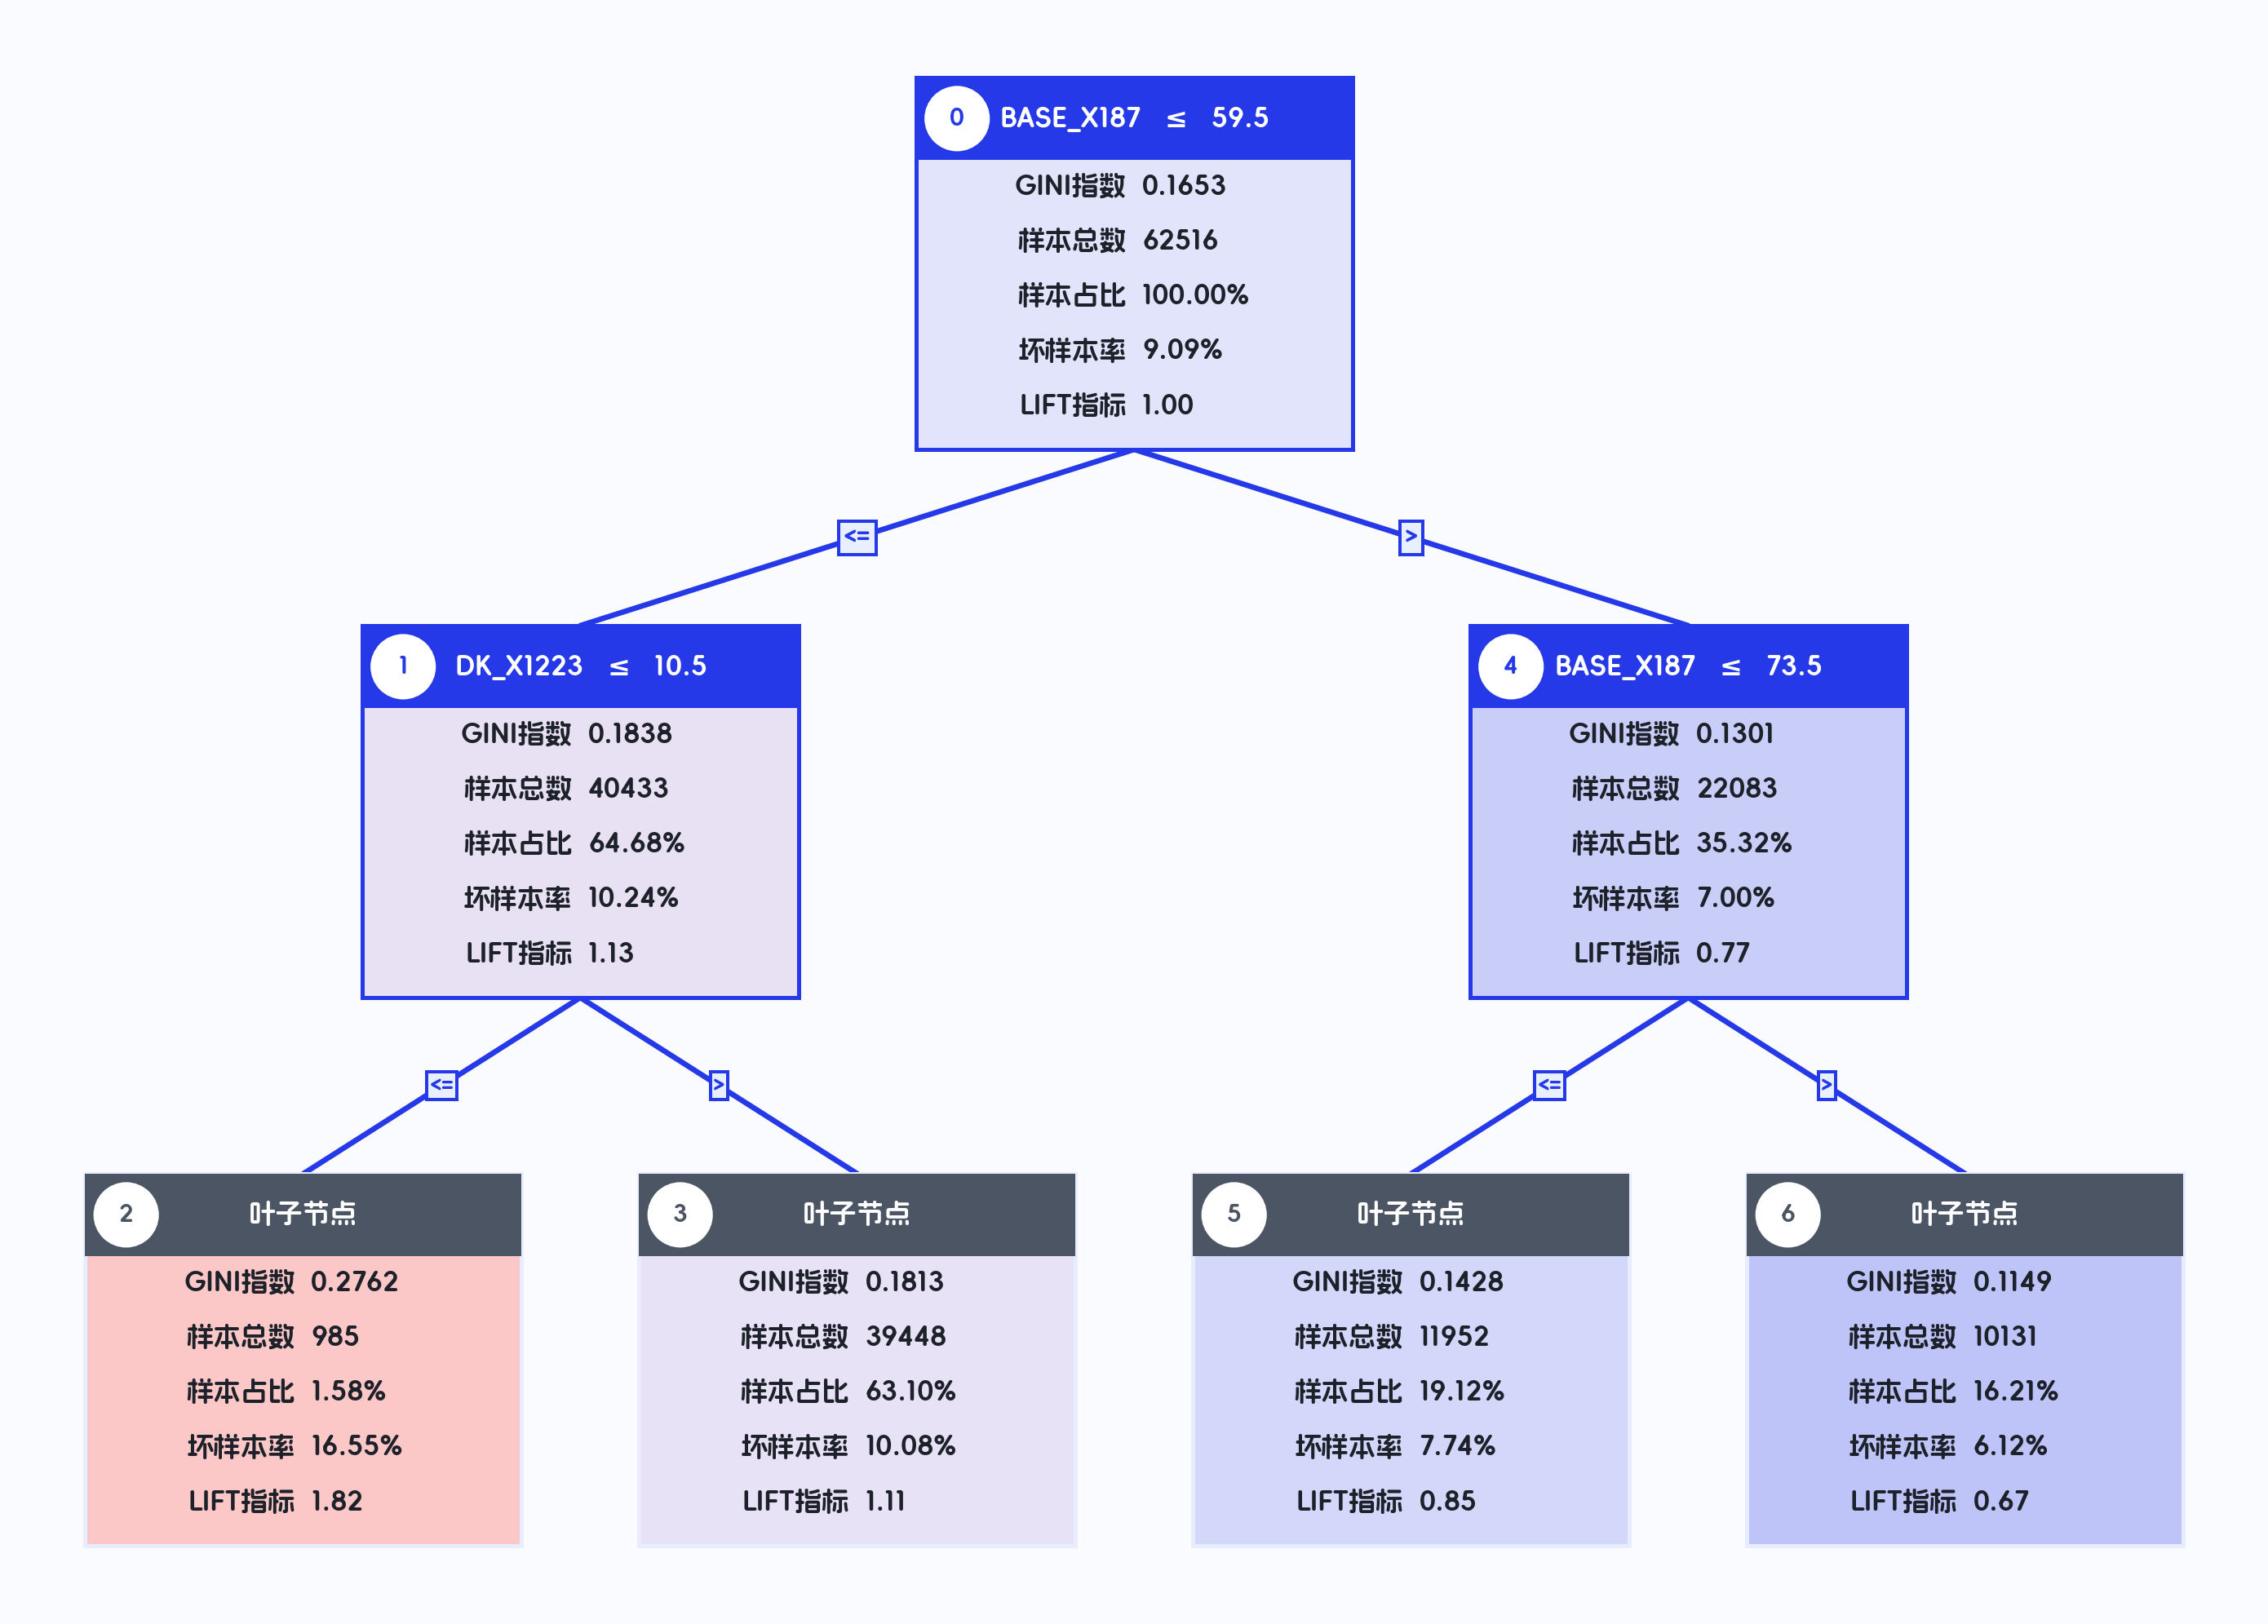

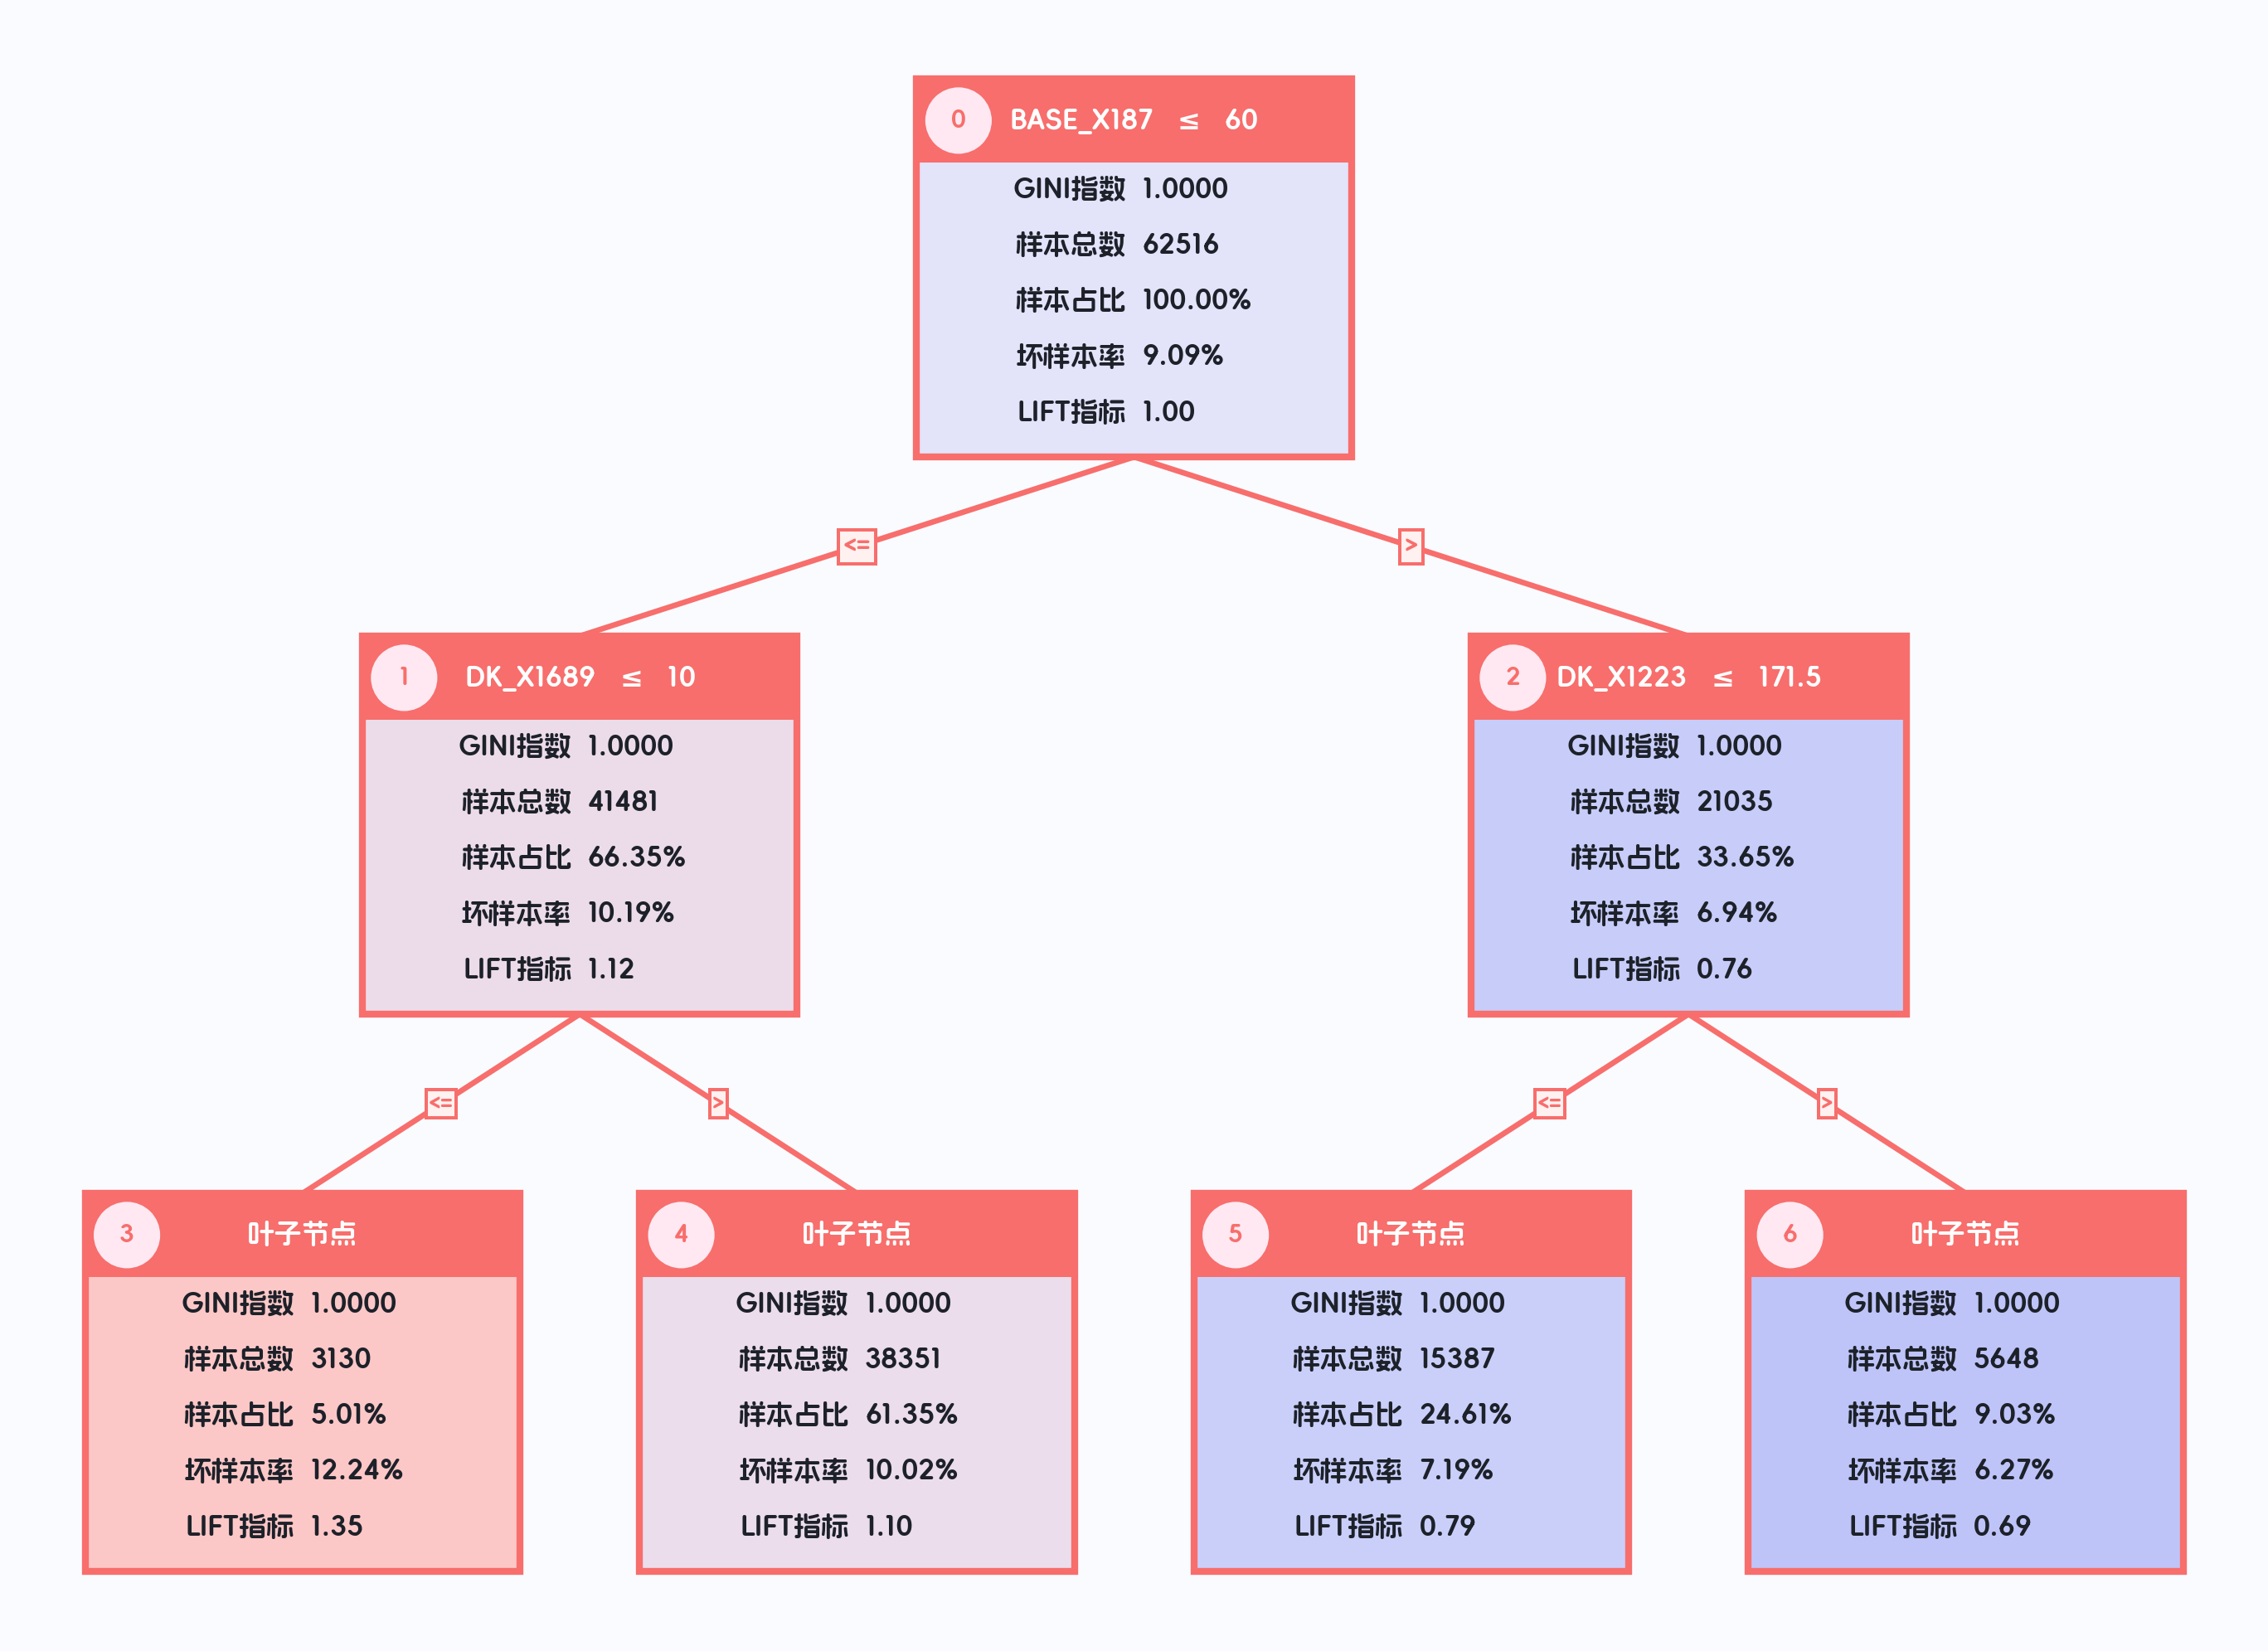

,节点编号,指标含义,组合策略,是否叶子,是否调整,规则分类,分箱,样本总数,样本占比,好样本数,...,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,3,BASE_X187 <= 60.0000 且 DK_X1689 <= 10.0000,(BASE_X187 <= 60.0) & (DK_X1689 <= 10.0),是,是,验证规则,命中,1083,0.0520,943,...,0.1293,1.3835,0.0210,0.4046,0.8680,0.1293,0.0719,0.0924,BASE_X187、DK_X1689,最近12个月多头查询次数、现行贷款账户数
1,4,BASE_X187 <= 60.0000 且 DK_X1689 > 10.0000(含缺失),(BASE_X187 <= 60.0) & ((DK_X1689 > 10.0) | (DK_X1689.isna())),是,是,验证规则,命中,12862,0.6172,11548,...,0.1022,1.0934,0.1506,0.2440,0.4154,0.1022,0.6749,0.1775,BASE_X187、DK_X1689,最近12个月多头查询次数、现行贷款账户数
2,5,BASE_X187 > 60.0000(含缺失) 且 DK_X1223 <= 171.5000,((BASE_X187 > 60.0) | (BASE_X187.isna())) & (DK_X1223 <= 171.5),是,是,验证规则,命中,5092,0.2444,4720,...,0.0731,0.7819,-0.0705,-0.2886,0.6979,0.0731,0.1911,0.1057,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
3,6,BASE_X187 > 60.0000(含缺失) 且 DK_X1223 > 171.5000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())) & ((DK_X1223 > 171.5) | (DK_X1223.isna())),是,是,验证规则,命中,1801,0.0864,1680,...,0.0672,0.7191,-0.0266,-0.3075,0.8317,0.0672,0.0621,0.0646,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数


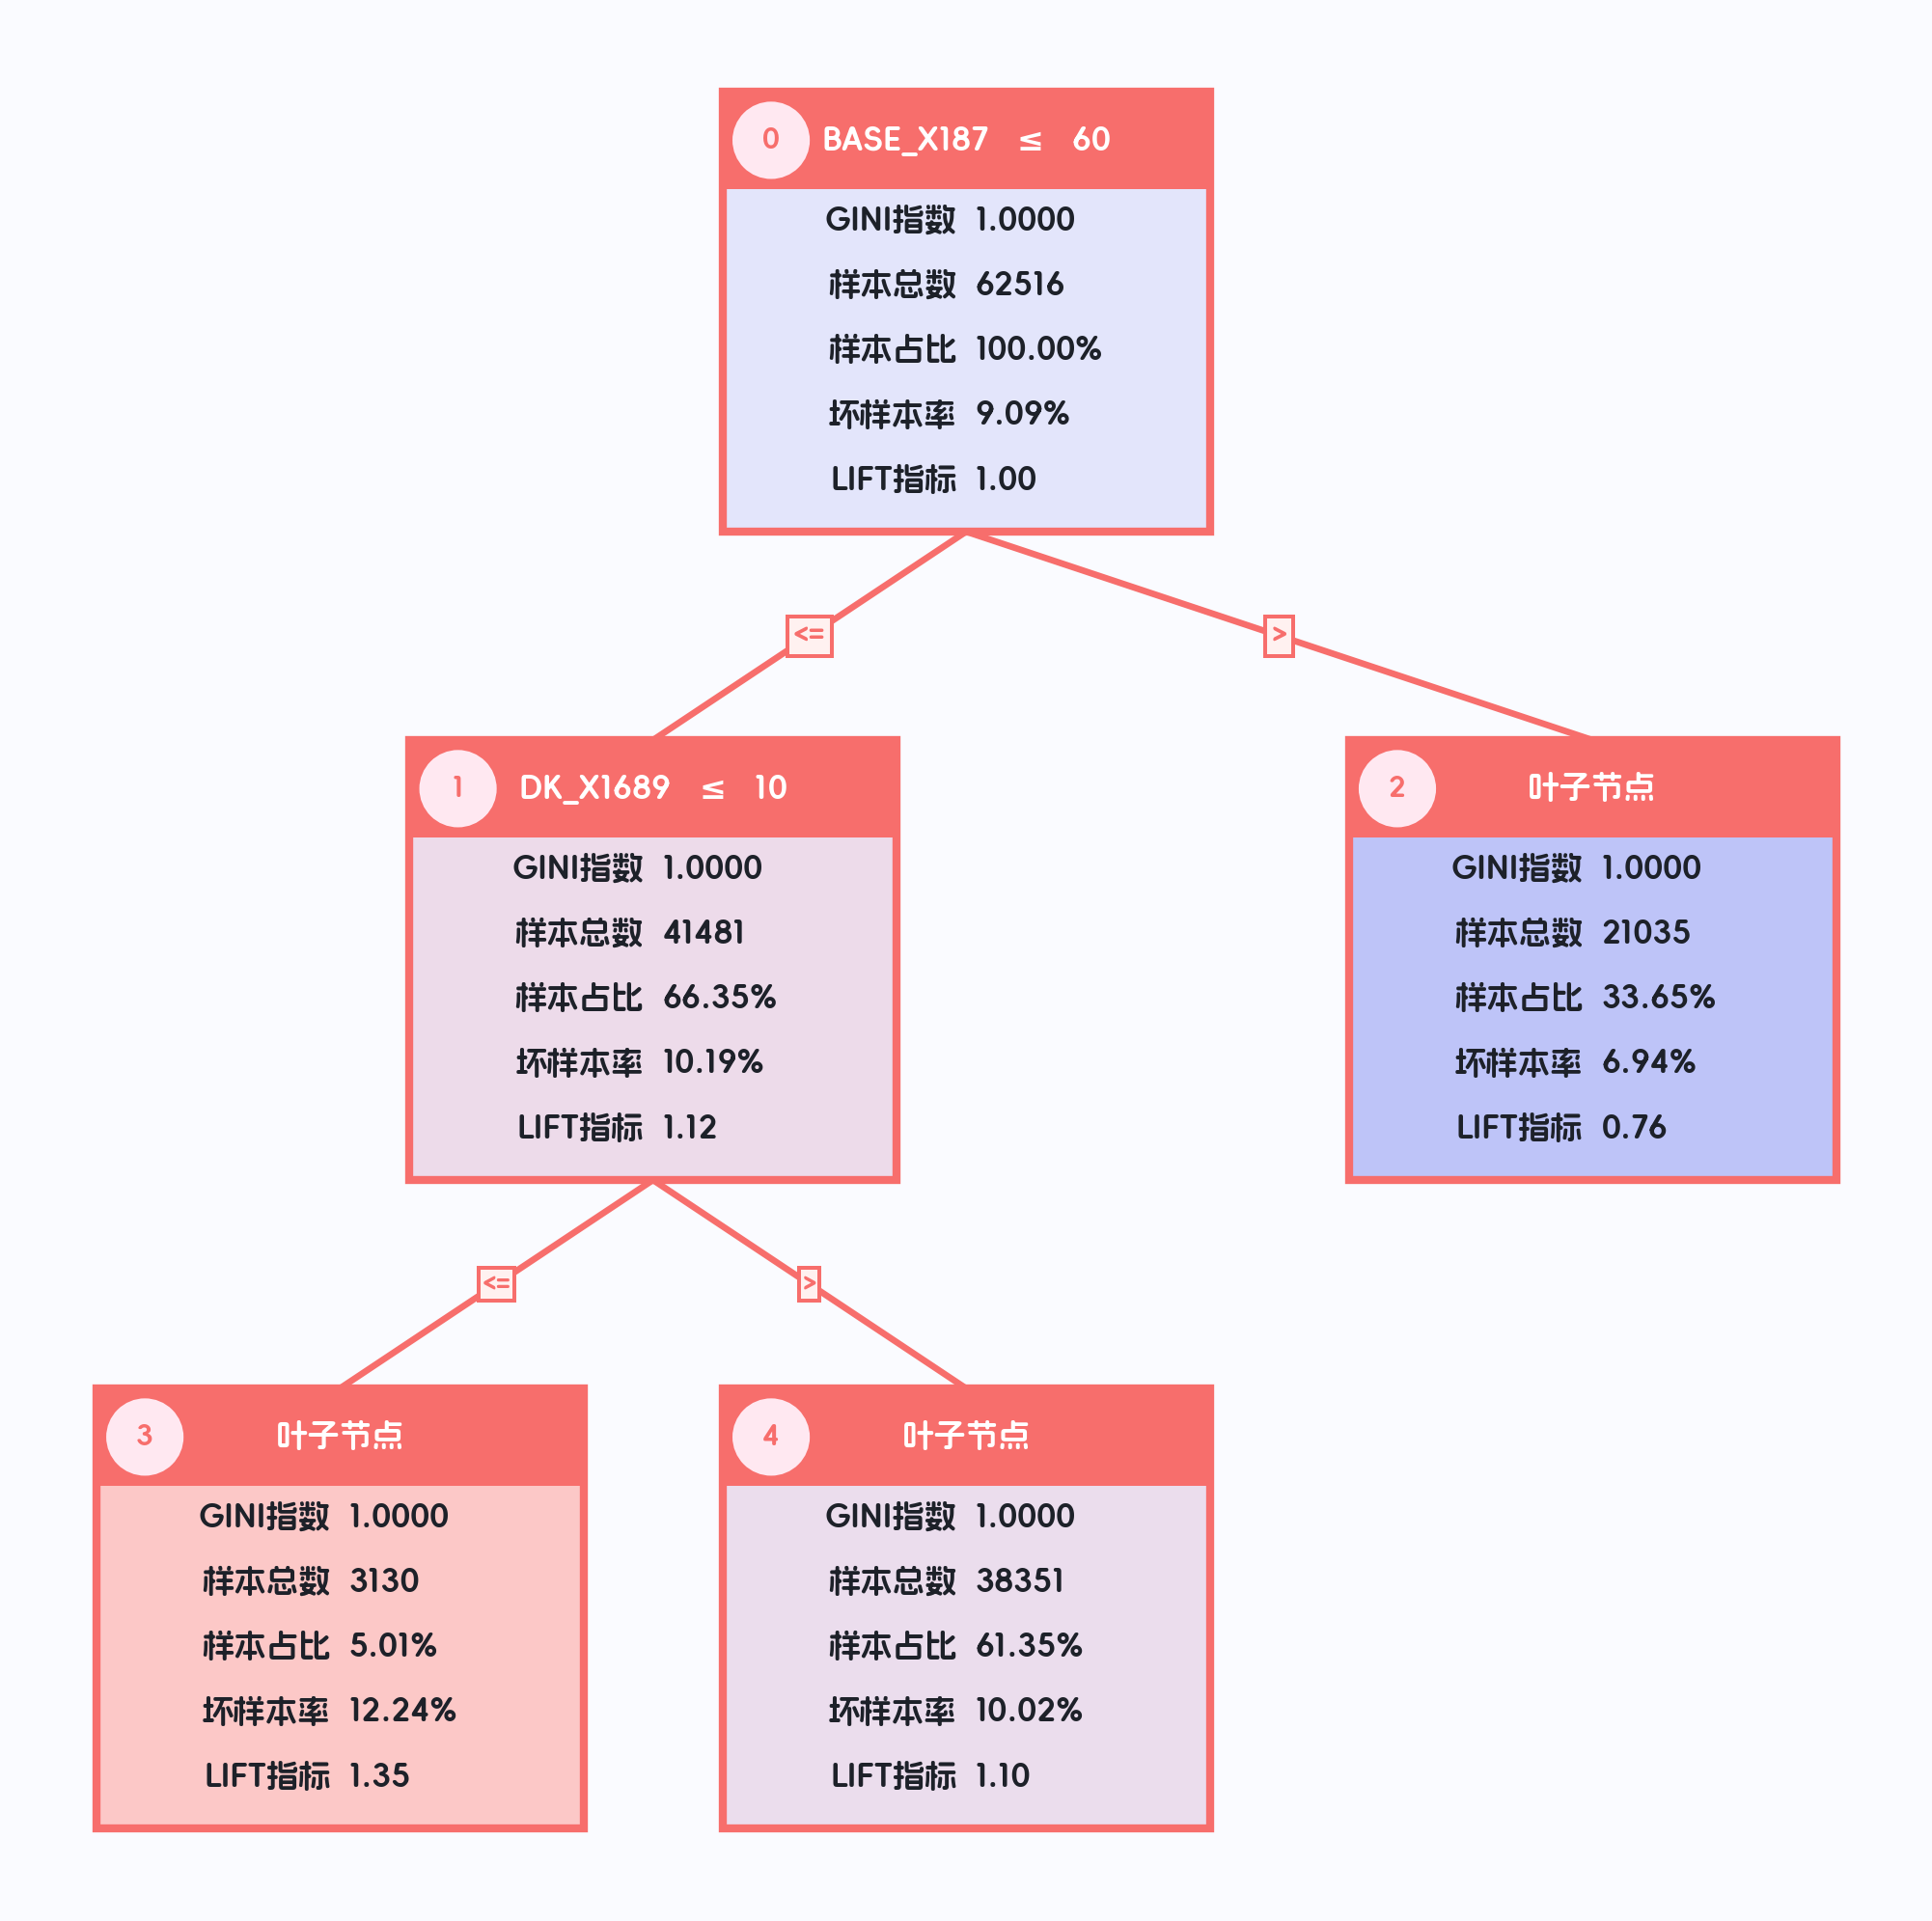

分箱详情                             MOB3 30+                                                   ...      MOB6 30+                                                                 
                                                              分箱           样本总数   样本占比           好样本数  好样本占比         坏样本数  坏样本占比   坏样本率  LIFT值    坏账改善  ...          坏样本数  坏样本占比   坏样本率  LIFT值    坏账改善   风险拒绝比    准确率    精确率    召回率   F1分数
0                                                           原始样本 128098000.0000 1.0000 121709000.0000 1.0000 6389000.0000 1.0000 0.0499 1.0000  0.0000  ... 11702000.0000 1.0000 0.0914 1.0000  0.0000  0.0000 0.0934 0.0934 1.0000 0.1709
1                      ((BASE_X187 > 60.0) | (BASE_X187.isna()))  46494000.0000 0.3630  44877000.0000 0.3687 1617000.0000 0.2531 0.0348 0.6973 -0.1725  ...  3306000.0000 0.2825 0.0711 0.7784 -0.1263 -0.3479 0.6231 0.0715 0.2532 0.1115
2                                                           剩余样本  81604000.0000 0.6370  76832000.0000 0.6313 4772000.0000 0.7469 0.0585 1.1725  0.3027  ...  8396000.0000 0.7175 0.1029 1.1263  0.2216  0.3479 0.3769 0.1043 0.7468 0.1830
3                       (BASE_X187 <= 60.0) & (DK_X1689 <= 10.0)   5286000.0000 0.0648   4870000.0000 0.0634  416000.0000 0.0872 0.0787 1.3458  0.0240  ...   699000.0000 0.0833 0.1322 1.2853  0.0198  0.3050 0.8381 0.1293 0.0963 0.1104
4                                                           剩余样本  76318000.0000 0.9352  71962000.0000 0.9366 4356000.0000 0.9128 0.0571 0.9760 -0.3458  ...  7697000.0000 0.9167 0.1009 0.9802 -0.2853 -0.3050 0.1619 0.1022 0.9037 0.1836
5  (BASE_X187 <= 60.0) & ((DK_X1689 > 10.0) | (DK_X1689.isna()))  76318000.0000 1.0000  71962000.0000 1.0000 4356000.0000 1.0000 0.0571 1.0000  1.0000  ...  7697000.0000 1.0000 0.1009 1.0000  1.0000     NaN 0.1022 0.1022 1.0000 0.1854
6                                                           剩余样本         0.0000 0.0000         0.0000 0.0000       0.0000 0.0000 0.0000 0.0000  0.0000  ...        0.0000 0.0000 0.0000 0.0000  0.0000  0.0000 0.8978 0.0000 0.0000 0.0000
7                                                           所有规则 128098000.0000 1.0000 121709000.0000 1.0000 6389000.0000 1.0000 0.0499 1.0000  1.0000  ... 11702000.0000 1.0000 0.0914 1.0000  1.0000     NaN 0.0934 0.0934 1.0000 0.1709

[8 rows x 27 columns]

训练集


,节点编号,指标含义,组合策略,是否叶子,是否调整,目标标签,规则分类,分箱,样本总数,样本占比,...,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,空规则,True,否,是,MOB1 30+,验证规则,命中,385418000.0000,1.0000,...,4826000.0000,1.0000,0.0125,1.0000,1.0000,NaN,0.0143,0.0143,1.0000,0.0282
1,0,空规则,True,否,是,MOB3 30+,验证规则,命中,385418000.0000,1.0000,...,18484000.0000,1.0000,0.0480,1.0000,1.0000,NaN,0.0516,0.0516,1.0000,0.0981
2,0,空规则,True,否,是,MOB6 30+,验证规则,命中,385418000.0000,1.0000,...,34496000.0000,1.0000,0.0895,1.0000,1.0000,NaN,0.0909,0.0909,1.0000,0.1667
3,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB1 30+,验证规则,命中,243386000.0000,0.6315,...,3868000.0000,0.8015,0.0159,1.2692,0.4613,0.7305,0.3453,0.0174,0.8096,0.0341
4,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB3 30+,验证规则,命中,243386000.0000,0.6315,...,13850000.0000,0.7493,0.0569,1.1866,0.3197,0.5063,0.3639,0.0595,0.7653,0.1105
5,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB6 30+,验证规则,命中,243386000.0000,0.6315,...,24881000.0000,0.7213,0.1022,1.1422,0.2436,0.3858,0.3807,0.1019,0.7432,0.1792
6,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB1 30+,验证规则,命中,142032000.0000,0.3685,...,958000.0000,0.1985,0.0067,0.5387,-0.2692,-0.7305,0.6547,0.0081,0.1904,0.0155
7,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB3 30+,验证规则,命中,142032000.0000,0.3685,...,4634000.0000,0.2507,0.0326,0.6803,-0.1866,-0.5063,0.6361,0.0360,0.2347,0.0624
8,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB6 30+,验证规则,命中,142032000.0000,0.3685,...,9615000.0000,0.2787,0.0677,0.7564,-0.1422,-0.3858,0.6193,0.0694,0.2568,0.1093
9,3,BASE_X187 <= 60.0000 且 DK_X1689 <= 10.0000,(BASE_X187 <= 60.0) & (DK_X1689 <= 10.0),是,是,MOB1 30+,验证规则,命中,15599000.0000,0.0405,...,470000.0000,0.0974,0.0301,2.4063,0.0593,1.4656,0.9387,0.0300,0.1053,0.0467


测试集


,节点编号,指标含义,组合策略,是否叶子,是否调整,目标标签,规则分类,分箱,样本总数,样本占比,...,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,空规则,True,否,是,MOB1 30+,验证规则,命中,128098000.0000,1.0000,...,1713000.0000,1.0000,0.0134,1.0000,1.0000,NaN,0.0154,0.0154,1.0000,0.0303
1,0,空规则,True,否,是,MOB3 30+,验证规则,命中,128098000.0000,1.0000,...,6389000.0000,1.0000,0.0499,1.0000,1.0000,NaN,0.0544,0.0544,1.0000,0.1032
2,0,空规则,True,否,是,MOB6 30+,验证规则,命中,128098000.0000,1.0000,...,11702000.0000,1.0000,0.0914,1.0000,1.0000,NaN,0.0934,0.0934,1.0000,0.1709
3,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB1 30+,验证规则,命中,81604000.0000,0.6370,...,1325000.0000,0.7735,0.0162,1.2142,0.3759,0.5901,0.3402,0.0186,0.8069,0.0363
4,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB3 30+,验证规则,命中,81604000.0000,0.6370,...,4772000.0000,0.7469,0.0585,1.1725,0.3027,0.4752,0.3610,0.0632,0.7778,0.1170
5,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB6 30+,验证规则,命中,81604000.0000,0.6370,...,8396000.0000,0.7175,0.1029,1.1263,0.2216,0.3479,0.3769,0.1043,0.7468,0.1830
6,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB1 30+,验证规则,命中,46494000.0000,0.3630,...,388000.0000,0.2265,0.0083,0.6241,-0.2142,-0.5901,0.6598,0.0090,0.1931,0.0172
7,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB3 30+,验证规则,命中,46494000.0000,0.3630,...,1617000.0000,0.2531,0.0348,0.6973,-0.1725,-0.4752,0.6390,0.0366,0.2222,0.0628
8,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB6 30+,验证规则,命中,46494000.0000,0.3630,...,3306000.0000,0.2825,0.0711,0.7784,-0.1263,-0.3479,0.6231,0.0715,0.2532,0.1115
9,3,BASE_X187 <= 60.0000 且 DK_X1689 <= 10.0000,(BASE_X187 <= 60.0) & (DK_X1689 <= 10.0),是,是,MOB1 30+,验证规则,命中,5286000.0000,0.0413,...,139000.0000,0.0811,0.0263,1.9664,0.0416,1.0080,0.9358,0.0305,0.1028,0.0470


OOT


,节点编号,指标含义,组合策略,是否叶子,是否调整,目标标签,规则分类,分箱,样本总数,样本占比,...,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,空规则,True,否,是,MOB1 30+,验证规则,命中,231379000.0000,1.0000,...,2263000.0000,1.0000,0.0098,1.0000,1.0000,NaN,0.0107,0.0107,1.0000,0.0213
1,0,空规则,True,否,是,MOB3 30+,验证规则,命中,231379000.0000,1.0000,...,9815000.0000,1.0000,0.0424,1.0000,1.0000,NaN,0.0450,0.0450,1.0000,0.0861
2,0,空规则,True,否,是,MOB6 30+,验证规则,命中,231379000.0000,1.0000,...,19829000.0000,1.0000,0.0857,1.0000,1.0000,NaN,0.0894,0.0894,1.0000,0.1641
3,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB1 30+,验证规则,命中,144416000.0000,0.6242,...,1821000.0000,0.8047,0.0126,1.2892,0.4803,0.7696,0.3372,0.0134,0.8339,0.0263
4,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB3 30+,验证规则,命中,144416000.0000,0.6242,...,7164000.0000,0.7299,0.0496,1.1694,0.2814,0.4508,0.3540,0.0514,0.7659,0.0963
5,1,BASE_X187 <= 60.0000,(BASE_X187 <= 60.0),否,是,MOB6 30+,验证规则,命中,144416000.0000,0.6242,...,14021000.0000,0.7071,0.0971,1.1329,0.2207,0.3536,0.3743,0.0998,0.7477,0.1760
6,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB1 30+,验证规则,命中,86963000.0000,0.3758,...,442000.0000,0.1953,0.0051,0.5197,-0.2892,-0.7696,0.6628,0.0054,0.1661,0.0105
7,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB3 30+,验证规则,命中,86963000.0000,0.3758,...,2651000.0000,0.2701,0.0305,0.7186,-0.1694,-0.4508,0.6460,0.0319,0.2341,0.0561
8,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,MOB6 30+,验证规则,命中,86963000.0000,0.3758,...,5808000.0000,0.2929,0.0668,0.7793,-0.1329,-0.3536,0.6257,0.0683,0.2523,0.1075
9,3,BASE_X187 <= 60.0000 且 DK_X1689 <= 10.0000,(BASE_X187 <= 60.0) & (DK_X1689 <= 10.0),是,是,MOB1 30+,验证规则,命中,5328000.0000,0.0230,...,131000.0000,0.0579,0.0246,2.5139,0.0357,1.5496,0.9600,0.0276,0.0797,0.0411


,节点编号,指标含义,组合策略,是否叶子,是否调整,规则分类,分箱,样本总数,样本占比,好样本数,...,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,2,BASE_X187 > 60.0000(含缺失),((BASE_X187 > 60.0) | (BASE_X187.isna())),是,是,验证规则,命中,6893,0.3308,6400,...,0.0715,0.7655,-0.1159,-0.3505,0.6231,0.0715,0.2532,0.1115,BASE_X187,最近12个月多头查询次数
1,3,BASE_X187 <= 60.0000 且 DK_X1689 <= 10.0000,(BASE_X187 <= 60.0) & (DK_X1689 <= 10.0),是,是,验证规则,命中,1083,0.0520,943,...,0.1293,1.3835,0.0210,0.4046,0.8680,0.1293,0.0719,0.0924,BASE_X187、DK_X1689,最近12个月多头查询次数、现行贷款账户数
2,4,BASE_X187 <= 60.0000 且 DK_X1689 > 10.0000(含缺失),(BASE_X187 <= 60.0) & ((DK_X1689 > 10.0) | (DK_X1689.isna())),是,是,验证规则,命中,12862,0.6172,11548,...,0.1022,1.0934,0.1506,0.2440,0.4154,0.1022,0.6749,0.1775,BASE_X187、DK_X1689,最近12个月多头查询次数、现行贷款账户数


C:\Users\18306\AppData\Local\Temp\hscredit_manual_tree_gr23obnj


In [1]:
import sys

sys.path.append("../")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from pathlib import Path
from tempfile import mkdtemp
from hscredit import init_setting
from hscredit.report.mining import DecisionTreeAnalyzer, ManualTreeExtractor
from hscredit.core.viz import plot_tree
from hscredit.report import ruleset_analysis
from hscredit.utils import save_pickle, load_pickle

from hscredit.core.model_selection import oot_split, group_train_test_split

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

features = ["BASE_X187", "DK_X1689", "DK_X1223", "DK_X2677"]
feature_map = {
    "BASE_X187": "最近12个月多头查询次数",
    "DK_X1689": "现行贷款账户数",
    "DK_X1223": "个人消费贷款账户数",
    "DK_X2677": "贷款本月应还金额",
}
target = "MOB6@30"
data[target] = data["MOB6"].gt(30).astype(int)
data["授信时间"] = pd.to_datetime(data["授信时间"])
data[features] = data[features].fillna(-99999)
oot_start = data["授信时间"].max().to_period("M").start_time
development, oot = oot_split(data, time_col="授信时间", oot_start=oot_start)
development = development.loc[~development["用户编码"].isin(oot["用户编码"])].copy()
train, test = group_train_test_split(development, group="用户编码", test_size=0.25, random_state=42)
datasets = {"训练集": train, "测试集": test, "OOT": oot}

init_setting()
baseline = DecisionTreeAnalyzer(
    target=target,
    features=features,
    tree_params={"max_depth": 2, "min_samples_leaf": 100},
    feature_map=feature_map,
    n_jobs=1,
)
baseline.fit(train)
display(baseline.get_rule_table())

tree = ManualTreeExtractor(
    target=target,
    features=features,
    max_depth=2,
    min_samples_leaf=100,
    feature_map=feature_map,
    random_state=42,
    n_jobs=1,
)
tree.fit(train)
display(plot_tree(tree))
tree.manual_split(train, feature="BASE_X187", threshold=60, node=0)
tree.manual_split(train, feature="DK_X1689", threshold=10, node=1)
tree.manual_split(train, feature="DK_X1223", threshold=None, node=2)
display(plot_tree(tree))
display(tree.get_rule_table(test, leaf_only=True))
tree.delete_node(node=2)
display(plot_tree(tree))

rules = tree.get_rules(leaf_only=True)
display(
    ruleset_analysis(
        test,
        rules=rules,
        overdue=["MOB3", "MOB6"],
        dpds=30,
        overdue_operator=">",
        amount="loan_amt",
        n_jobs=1,
    )
)
output = Path(mkdtemp(prefix="hscredit_manual_tree_"))
report = tree.report(
    datasets,
    overdue=["MOB1", "MOB3", "MOB6"],
    dpds=30,
    overdue_operator=">",
    amount="loan_amt",
    date="授信时间",
    group="GROUP",
    methods="quantile",
    save=str(output / "人工二叉树报告.xlsx"),
)
for name, table in report.items():
    print(name)
    display(table)
save_pickle(tree, output / "人工二叉树.pkl")
restored = load_pickle(output / "人工二叉树.pkl")
display(restored.get_rule_table(test, leaf_only=True))
print(output)

plt.close("all")

## 6. 多叉树：剪枝、指定切点、局部生长和报告

多叉树使用相同数据口径，代码完全独立，不需要前面的二叉树。

,节点编号,父节点,深度,是否叶子,分裂特征,切分点,类别分组,子节点,缺失分支,缺失独立分支,...,类别_1样本数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比
0,0,<NA>,0,否,BASE_X187,"[42.0, 61.0]",[],"[1, 2, 3]",0,否,...,5685,1.0000,56831,1.0000,5685,1.0000,0.0909,1.0000,1.0000,NaN
1,1,0,1,否,DK_X1223,"[15.0, 57.0]",[],"[4, 5, 6]",0,否,...,2359,0.3409,18955,0.3335,2359,0.4150,0.1107,1.2171,0.1123,0.3294
2,2,0,1,否,DK_X2677,"[32893.99999999999, 39149.75]",[],"[7, 8, 9]",0,否,...,1952,0.3387,19220,0.3382,1952,0.3434,0.0922,1.0139,0.0071,0.0210
3,3,0,1,否,BASE_X187,[74.0],[],"[10, 11]",0,否,...,1374,0.3204,18656,0.3283,1374,0.2417,0.0686,0.7543,-0.1158,-0.3615
4,4,1,2,是,,[],[],[],0,否,...,272,0.0313,1682,0.0296,272,0.0478,0.1392,1.5308,0.0171,0.5479
5,5,1,2,是,,[],[],[],0,否,...,1091,0.1681,9415,0.1657,1091,0.1919,0.1038,1.1420,0.0287,0.1706
6,6,1,2,是,,[],[],[],0,否,...,996,0.1416,7858,0.1383,996,0.1752,0.1125,1.2370,0.0391,0.2761
7,7,2,2,是,,[],[],[],0,否,...,1296,0.2258,12818,0.2255,1296,0.2280,0.0918,1.0098,0.0028,0.0126
8,8,2,2,是,,[],[],[],0,否,...,197,0.0282,1568,0.0276,197,0.0347,0.1116,1.2274,0.0066,0.2340
9,9,2,2,是,,[],[],[],0,否,...,459,0.0847,4834,0.0851,459,0.0807,0.0867,0.9536,-0.0043,-0.0507


,分裂特征,切分点,类别分组,分支数,缺失分支,缺失独立分支,卡方值,P值,调整后P值,分裂增益,分裂价值
0,BASE_X187,"[42.0, 61.0]",[],3,0,否,221.8121,0.0000,0.0000,0.0006,48.1659
1,DK_X1689,"[13.0, 35.0]",[],3,0,否,106.5113,0.0000,0.0000,0.0003,23.1286
2,DK_X1223,"[26.0, 131.0]",[],3,0,否,86.2920,0.0000,0.0000,0.0002,18.7381
3,DK_X2677,"[6713.0, 39844.25]",[],3,0,否,71.2360,0.0000,0.0000,0.0002,15.4687


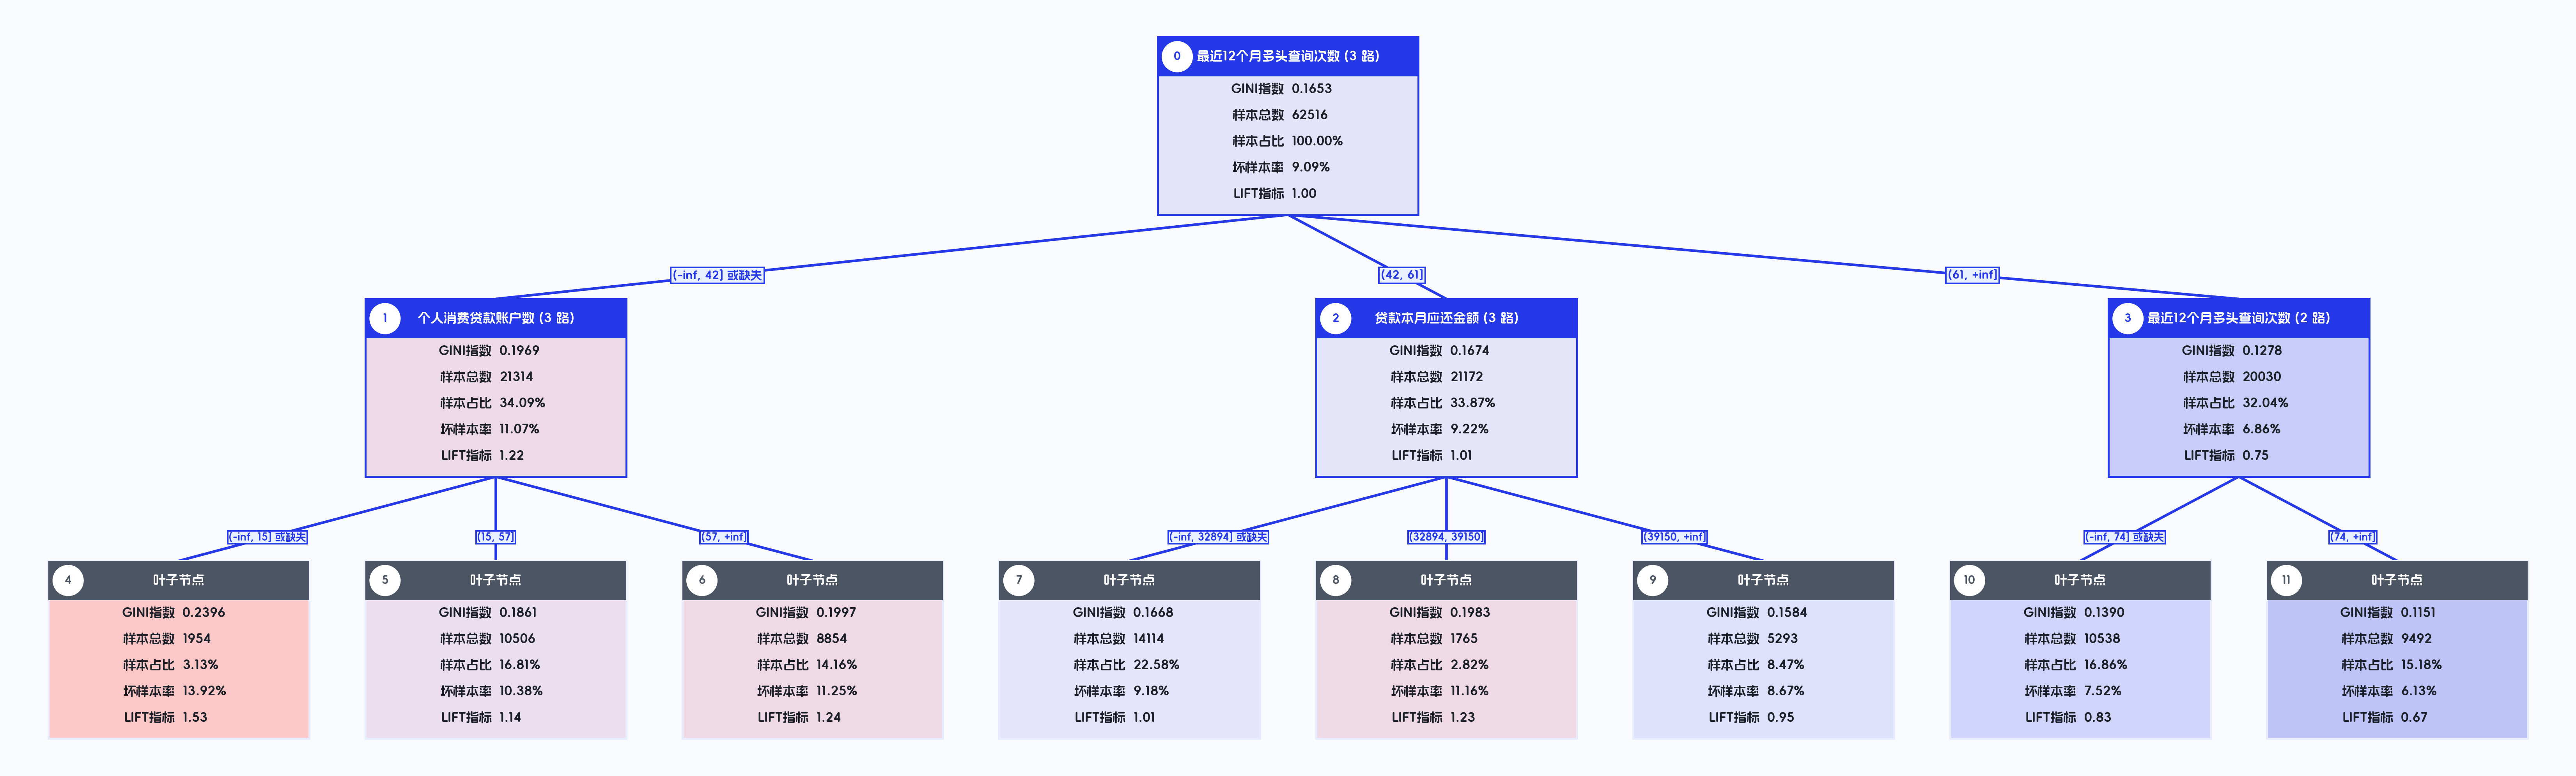

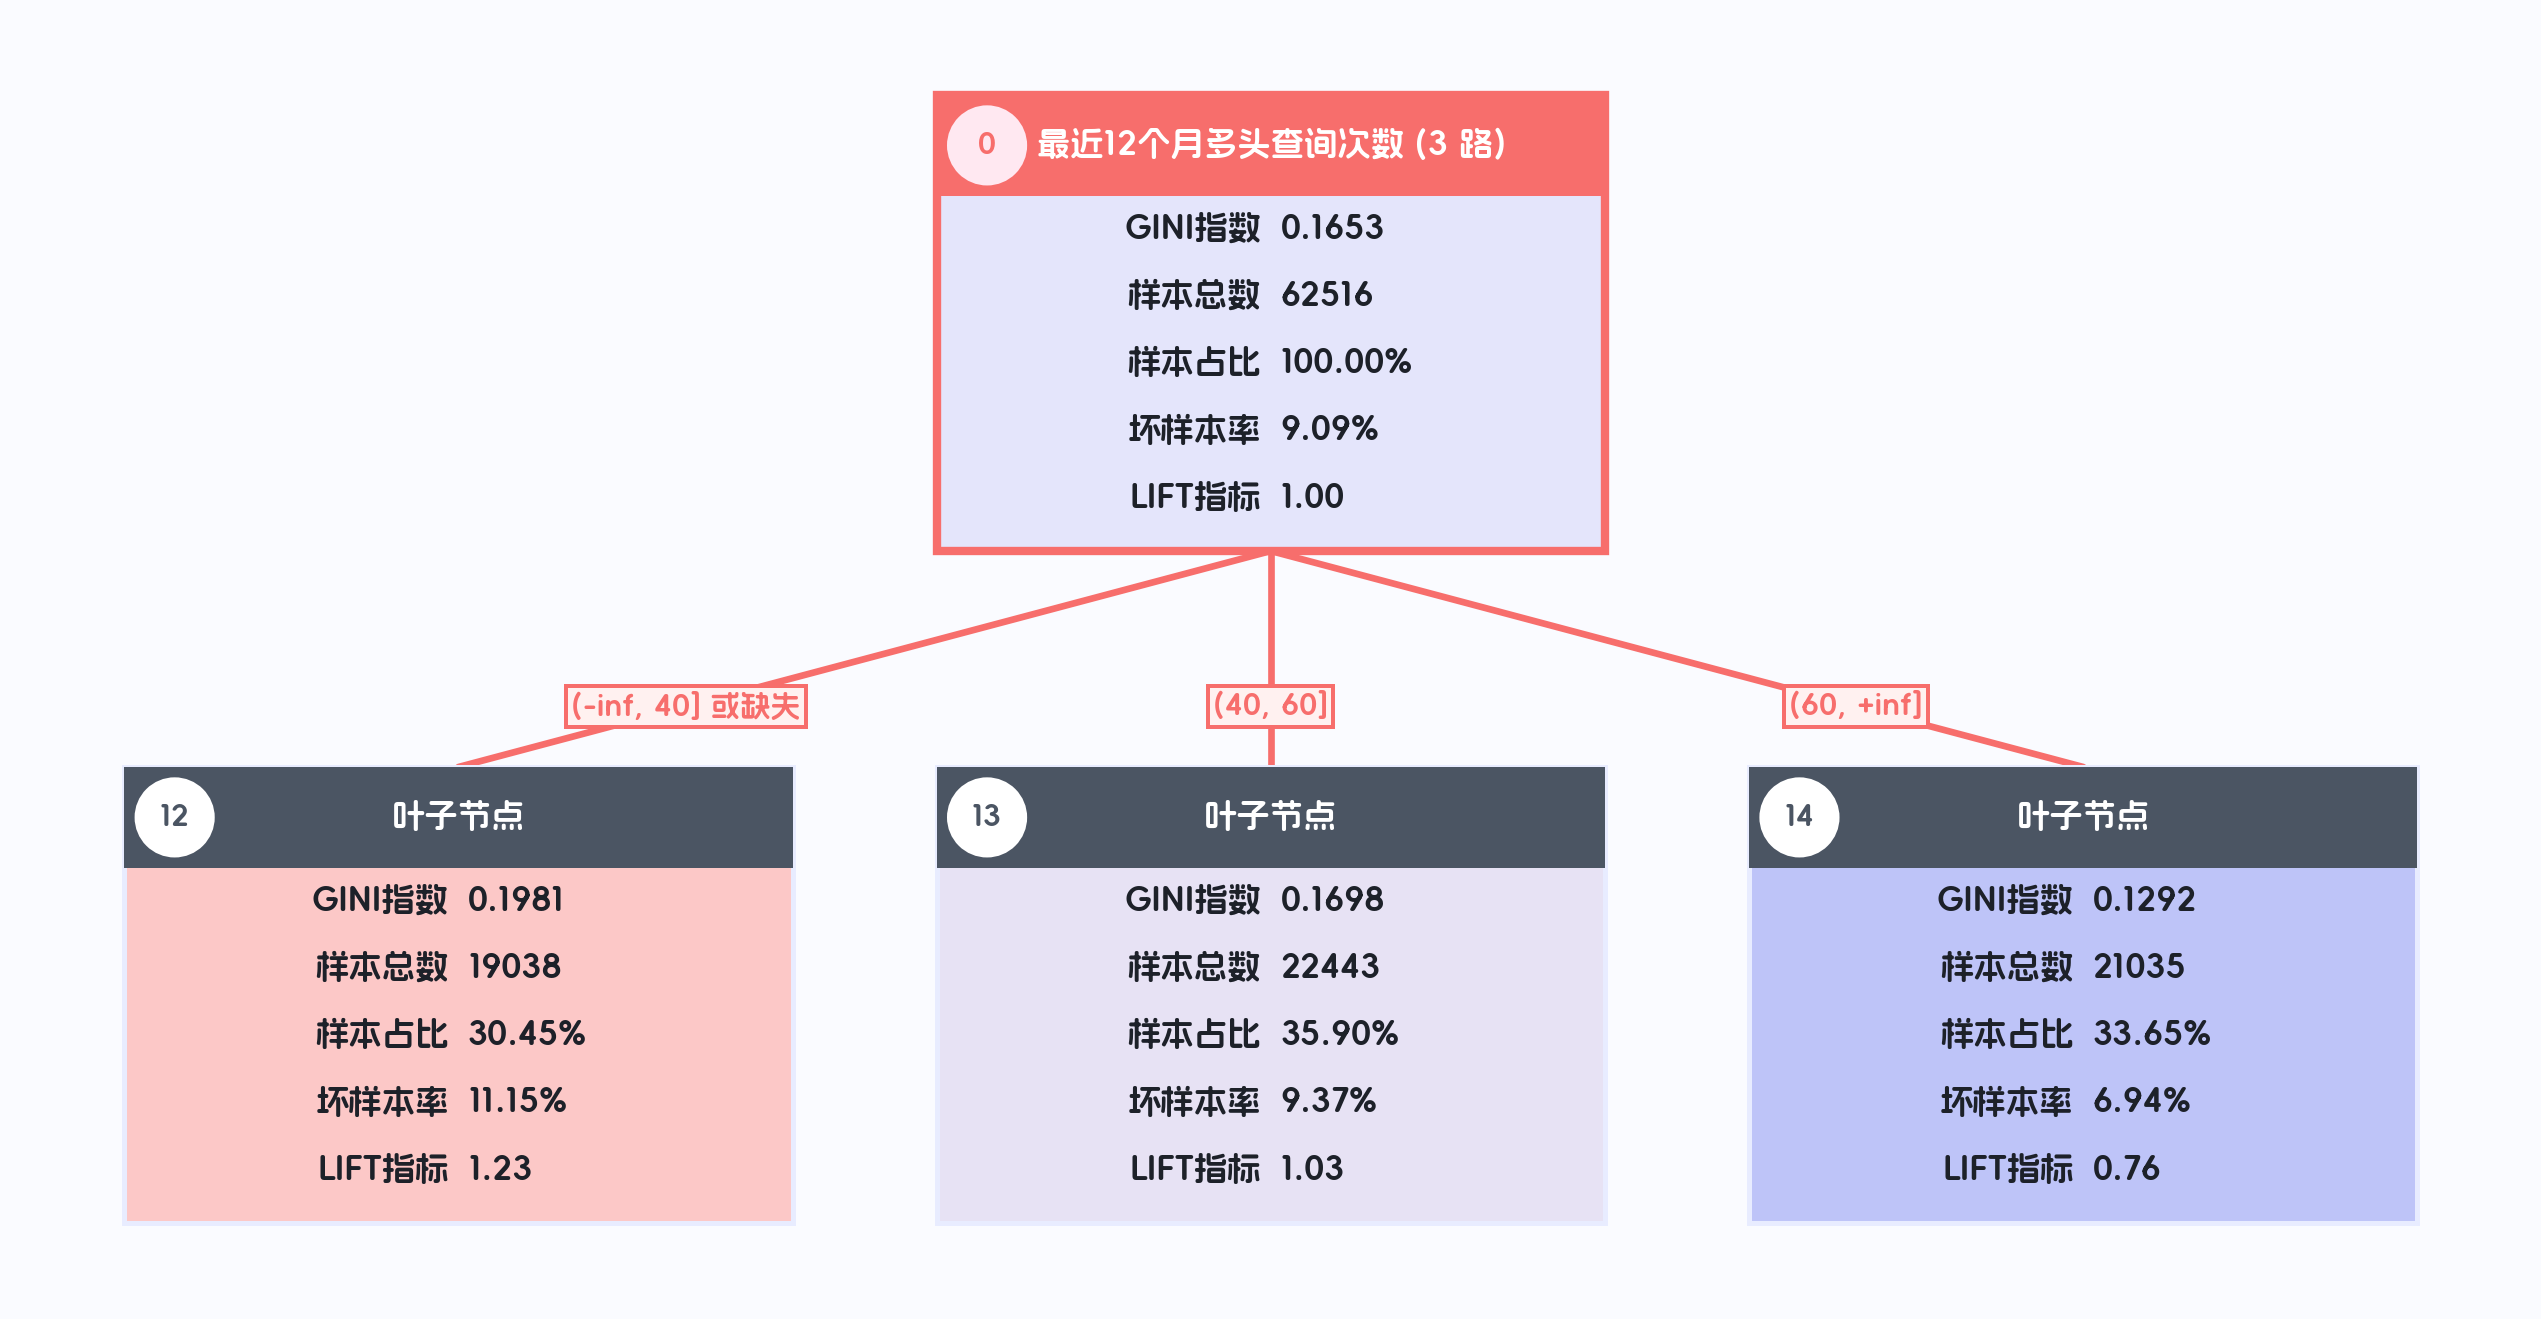

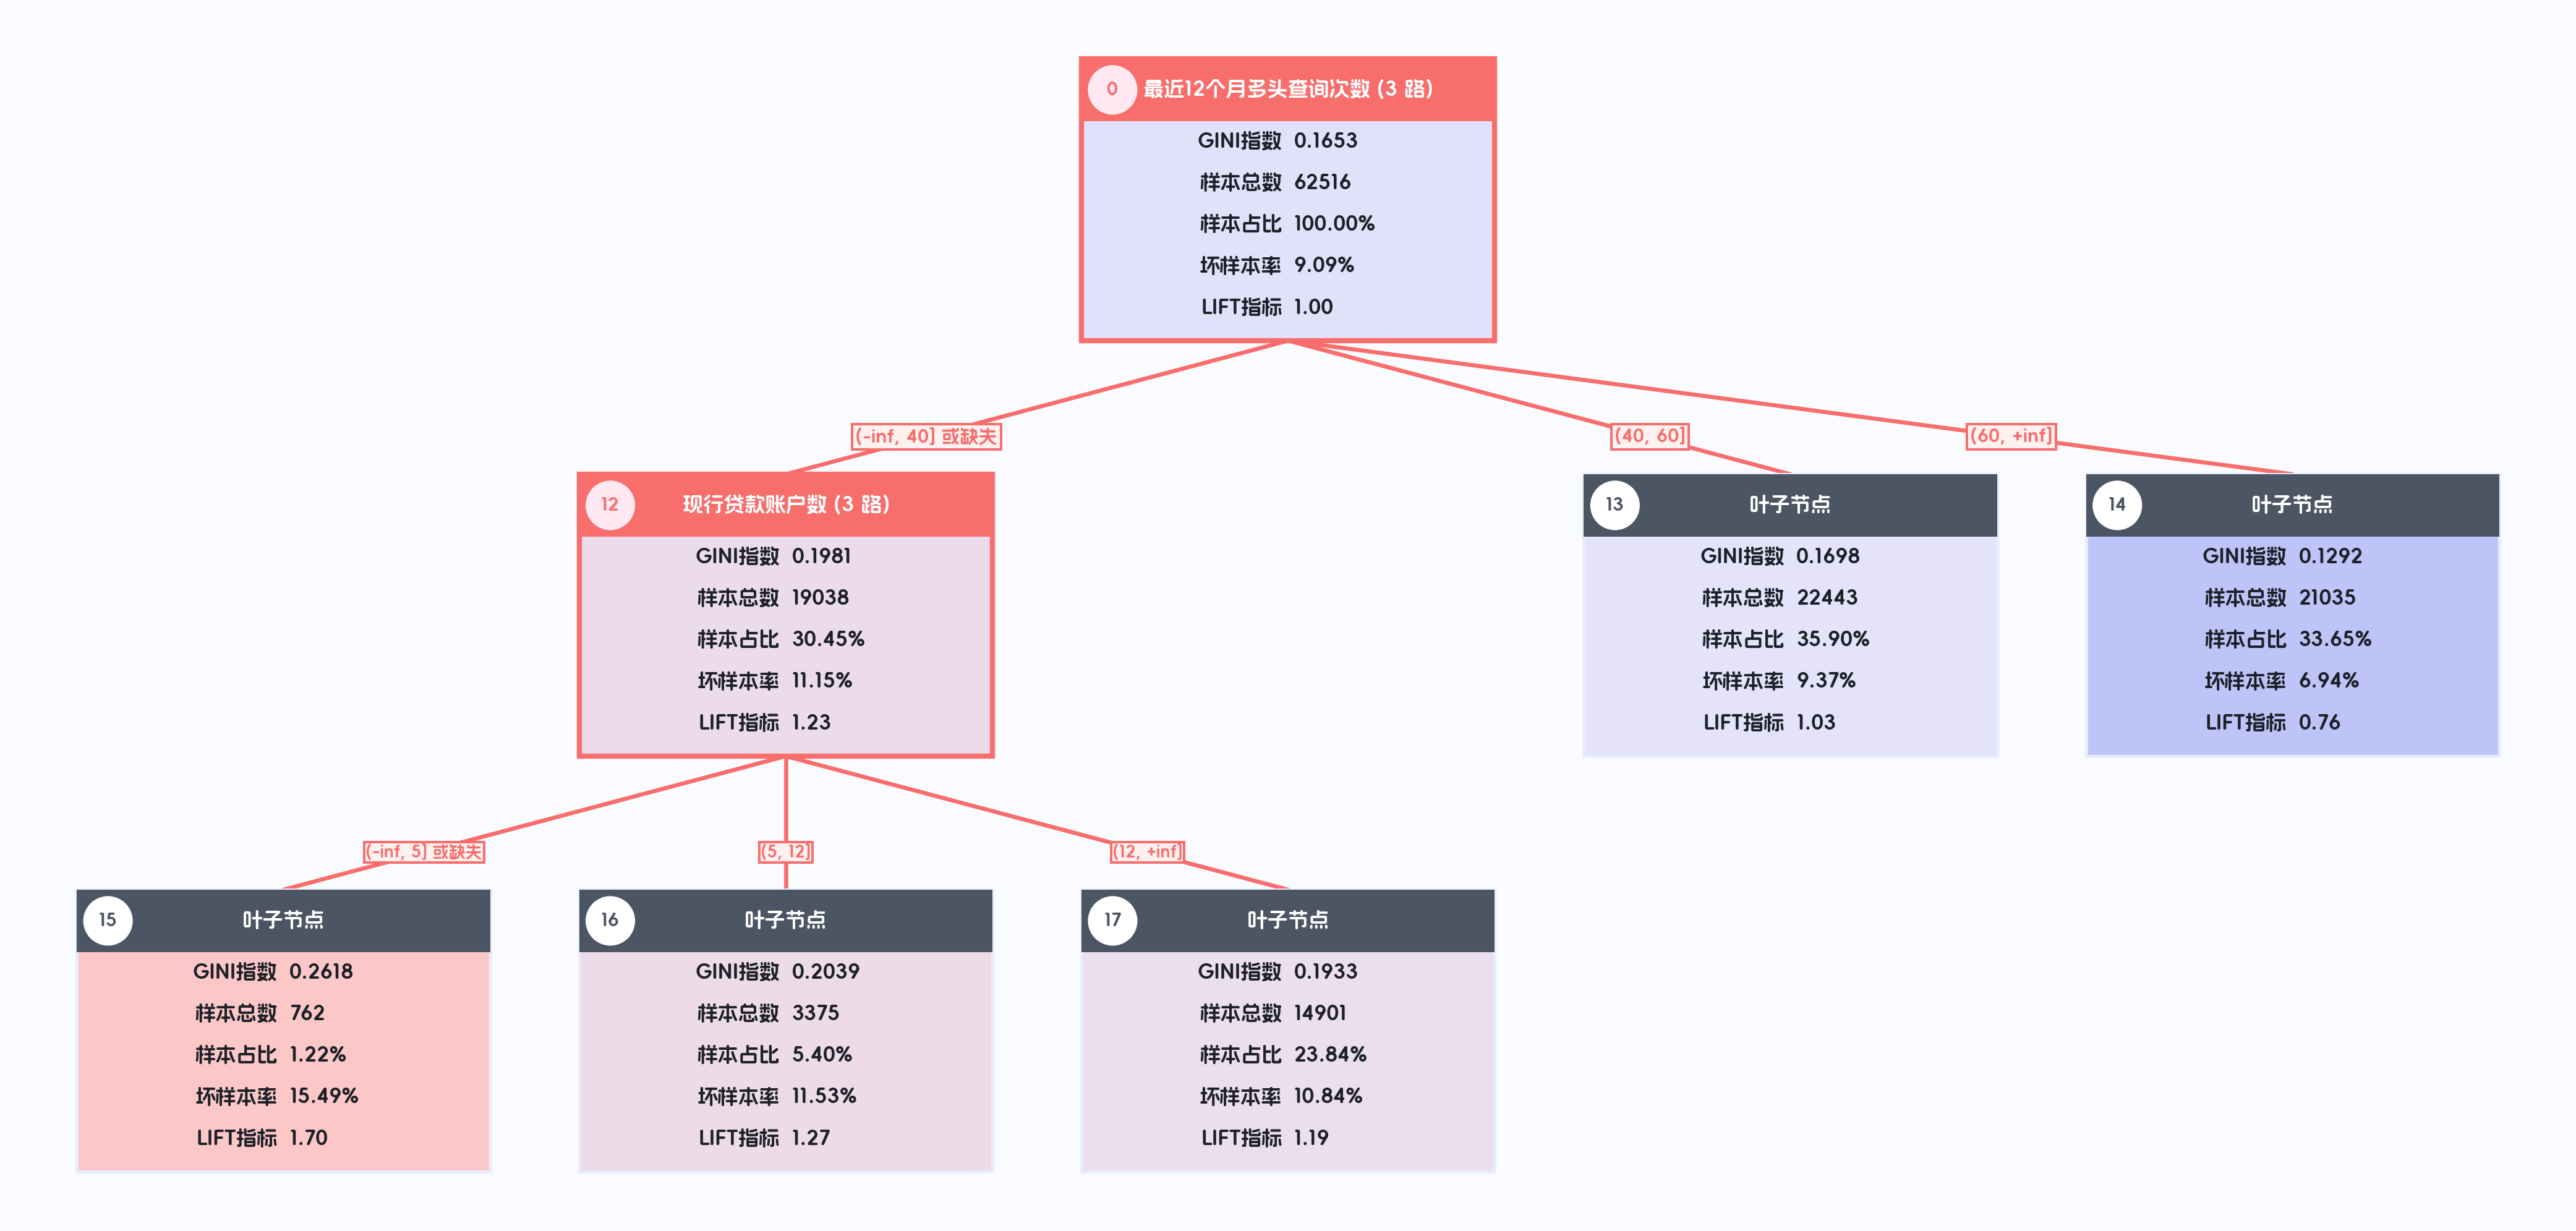

,节点编号,指标含义,组合策略,是否叶子,是否调整,规则分类,分箱,样本总数,样本占比,好样本数,...,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,0,全部样本,True,否,是,验证规则,命中,62516,1.0000,56831,...,0.0909,1.0000,1.0000,NaN,0.0909,0.0909,1.0000,0.1667,,
1,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,验证规则,命中,19038,0.3045,16916,...,0.1115,1.2257,0.0988,0.3245,0.6724,0.1115,0.3733,0.1717,BASE_X187,最近12个月多头查询次数
2,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,验证规则,命中,22443,0.3590,20340,...,0.0937,1.0304,0.0170,0.0475,0.6173,0.0937,0.3699,0.1495,BASE_X187,最近12个月多头查询次数
3,14,"BASE_X187: (60, +inf]",((BASE_X187 > 60.0)),是,是,验证规则,命中,21035,0.3365,19575,...,0.0694,0.7633,-0.1201,-0.3568,0.6193,0.0694,0.2568,0.1093,BASE_X187,最近12个月多头查询次数
4,18,"BASE_X187: (-inf, 40] 或缺失 且 DK_X1223: (-inf, 14] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 <= 14.0) | (DK_X1223.isna())),是,是,验证规则,命中,1711,0.0274,1464,...,0.1444,1.5875,0.0165,0.6040,0.8896,0.1444,0.0434,0.0668,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
5,19,"BASE_X187: (-inf, 40] 或缺失 且 DK_X1223: (14, 40]",((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 > 14.0) & (DK_X1223 <= 40.0)),是,是,验证规则,命中,6416,0.1026,5762,...,0.1019,1.1209,0.0138,0.1347,0.8274,0.1019,0.1150,0.1081,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
6,20,"BASE_X187: (-inf, 40] 或缺失 且 DK_X1223: (40, +inf]",((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 > 40.0)),是,是,验证规则,命中,10911,0.1745,9690,...,0.1119,1.2306,0.0488,0.2793,0.7736,0.1119,0.2148,0.1471,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数


分箱详情                             MOB3 30+                                                   ...      MOB6 30+                                                                 
                                                                                       分箱           样本总数   样本占比           好样本数  好样本占比         坏样本数  坏样本占比   坏样本率  LIFT值    坏账改善  ...          坏样本数  坏样本占比   坏样本率  LIFT值    坏账改善   风险拒绝比    准确率    精确率    召回率   F1分数
0                                                                                    原始样本 128098000.0000 1.0000 121709000.0000 1.0000 6389000.0000 1.0000 0.0499 1.0000  0.0000  ... 11702000.0000 1.0000 0.0914 1.0000  0.0000  0.0000 0.0934 0.0934 1.0000 0.1709
1                                              ((BASE_X187 > 40.0) & (BASE_X187 <= 60.0))  46607000.0000 0.3638  44276000.0000 0.3638 2331000.0000 0.3648 0.0500 1.0028  0.0016  ...  4365000.0000 0.3730 0.0937 1.0252  0.0144  0.0396 0.6124 0.0953 0.3708 0.1517
2                                                                                    剩余样本  81491000.0000 0.6362  77433000.0000 0.6362 4058000.0000 0.6352 0.0498 0.9984 -0.0028  ...  7337000.0000 0.6270 0.0900 0.9856 -0.0252 -0.0396 0.3876 0.0924 0.6292 0.1611
3                                                                    ((BASE_X187 > 60.0))  46494000.0000 0.5705  44877000.0000 0.5796 1617000.0000 0.3985 0.0348 0.6984 -0.4007  ...  3306000.0000 0.4506 0.0711 0.7898 -0.2793 -0.4895 0.4623 0.0715 0.4024 0.1215
4                                                                                    剩余样本  34997000.0000 0.4295  32556000.0000 0.4204 2441000.0000 0.6015 0.0697 1.4007  0.3016  ...  4031000.0000 0.5494 0.1152 1.2793  0.2102  0.4895 0.5377 0.1149 0.5976 0.1927
5   ((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 <= 14.0) | (DK_X1223.isna()))   3076000.0000 0.0879   2834000.0000 0.0871  242000.0000 0.0991 0.0787 1.1280  0.0123  ...   440000.0000 0.1092 0.1430 1.2419  0.0233  0.2652 0.8159 0.1391 0.1161 0.1266
6                                                                                    剩余样本  31921000.0000 0.9121  29722000.0000 0.9129 2199000.0000 0.9009 0.0689 0.9877 -0.1280  ...  3591000.0000 0.8908 0.1125 0.9767 -0.2419 -0.2652 0.1841 0.1123 0.8839 0.1993
7   ((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 > 14.0) & (DK_X1223 <= 40.0))  11311000.0000 0.3543  10578000.0000 0.3559  733000.0000 0.3333 0.0648 0.9407 -0.0325  ...  1200000.0000 0.3342 0.1061 0.9431 -0.0312 -0.0882 0.5927 0.1062 0.3539 0.1633
8                                                                                    剩余样本  20610000.0000 0.6457  19144000.0000 0.6441 1466000.0000 0.6667 0.0711 1.0325  0.0593  ...  2391000.0000 0.6658 0.1160 1.0312  0.0569  0.0882 0.4073 0.1160 0.6461 0.1967
9                        ((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 > 40.0))  20610000.0000 1.0000  19144000.0000 1.0000 1466000.0000 1.0000 0.0711 1.0000  1.0000  ...  2391000.0000 1.0000 0.1160 1.0000  1.0000     NaN 0.1160 0.1160 1.0000 0.2079
10                                                                                   剩余样本         0.0000 0.0000         0.0000 0.0000       0.0000 0.0000 0.0000 0.0000  0.0000  ...        0.0000 0.0000 0.0000 0.0000  0.0000  0.0000 0.8840 0.0000 0.0000 0.0000
11                                                                                   所有规则 128098000.0000 1.0000 121709000.0000 1.0000 6389000.0000 1.0000 0.0499 1.0000  1.0000  ... 11702000.0000 1.0000 0.0914 1.0000  1.0000     NaN 0.0934 0.0934 1.0000 0.1709

[12 rows x 27 columns]

训练集


,节点编号,指标含义,组合策略,是否叶子,是否调整,目标标签,规则分类,分箱,样本总数,样本占比,...,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,是,MOB1 30+,验证规则,命中,385418000.0000,1.0000,...,4826000.0000,1.0000,0.0125,1.0000,1.0000,NaN,0.0143,0.0143,1.0000,0.0282
1,0,全部样本,True,否,是,MOB3 30+,验证规则,命中,385418000.0000,1.0000,...,18484000.0000,1.0000,0.0480,1.0000,1.0000,NaN,0.0516,0.0516,1.0000,0.0981
2,0,全部样本,True,否,是,MOB6 30+,验证规则,命中,385418000.0000,1.0000,...,34496000.0000,1.0000,0.0895,1.0000,1.0000,NaN,0.0909,0.0909,1.0000,0.1667
3,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB1 30+,验证规则,命中,105402000.0000,0.2735,...,2062000.0000,0.4273,0.0196,1.5624,0.2117,0.7741,0.6941,0.0212,0.4513,0.0404
4,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB3 30+,验证规则,命中,105402000.0000,0.2735,...,6826000.0000,0.3693,0.0648,1.3504,0.1319,0.4823,0.6848,0.0673,0.3971,0.1151
5,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB6 30+,验证规则,命中,105402000.0000,0.2735,...,11907000.0000,0.3452,0.1130,1.2622,0.0987,0.3609,0.6724,0.1115,0.3733,0.1717
6,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB1 30+,验证规则,命中,137984000.0000,0.3580,...,1806000.0000,0.3742,0.0131,1.0453,0.0253,0.0705,0.6370,0.0143,0.3583,0.0274
7,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB3 30+,验证规则,命中,137984000.0000,0.3580,...,7024000.0000,0.3800,0.0509,1.0614,0.0343,0.0957,0.6274,0.0529,0.3683,0.0926
8,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB6 30+,验证规则,命中,137984000.0000,0.3580,...,12974000.0000,0.3761,0.0940,1.0505,0.0282,0.0787,0.6173,0.0937,0.3699,0.1495
9,14,"BASE_X187: (60, +inf]",((BASE_X187 > 60.0)),是,是,MOB1 30+,验证规则,命中,142032000.0000,0.3685,...,958000.0000,0.1985,0.0067,0.5387,-0.2692,-0.7305,0.6547,0.0081,0.1904,0.0155


测试集


,节点编号,指标含义,组合策略,是否叶子,是否调整,目标标签,规则分类,分箱,样本总数,样本占比,...,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,是,MOB1 30+,验证规则,命中,128098000.0000,1.0000,...,1713000.0000,1.0000,0.0134,1.0000,1.0000,NaN,0.0154,0.0154,1.0000,0.0303
1,0,全部样本,True,否,是,MOB3 30+,验证规则,命中,128098000.0000,1.0000,...,6389000.0000,1.0000,0.0499,1.0000,1.0000,NaN,0.0544,0.0544,1.0000,0.1032
2,0,全部样本,True,否,是,MOB6 30+,验证规则,命中,128098000.0000,1.0000,...,11702000.0000,1.0000,0.0914,1.0000,1.0000,NaN,0.0934,0.0934,1.0000,0.1709
3,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB1 30+,验证规则,命中,34997000.0000,0.2732,...,697000.0000,0.4069,0.0199,1.4893,0.1839,0.6733,0.6927,0.0226,0.4486,0.0430
4,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB3 30+,验证规则,命中,34997000.0000,0.2732,...,2441000.0000,0.3821,0.0697,1.3984,0.1498,0.5482,0.6849,0.0736,0.4136,0.1250
5,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB6 30+,验证规则,命中,34997000.0000,0.2732,...,4031000.0000,0.3445,0.1152,1.2609,0.0981,0.3589,0.6711,0.1149,0.3760,0.1760
6,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB1 30+,验证规则,命中,46607000.0000,0.3638,...,628000.0000,0.3666,0.0135,1.0076,0.0044,0.0120,0.6322,0.0152,0.3583,0.0291
7,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB3 30+,验证规则,命中,46607000.0000,0.3638,...,2331000.0000,0.3648,0.0500,1.0028,0.0016,0.0044,0.6217,0.0545,0.3642,0.0949
8,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB6 30+,验证规则,命中,46607000.0000,0.3638,...,4365000.0000,0.3730,0.0937,1.0252,0.0144,0.0396,0.6124,0.0953,0.3708,0.1517
9,14,"BASE_X187: (60, +inf]",((BASE_X187 > 60.0)),是,是,MOB1 30+,验证规则,命中,46494000.0000,0.3630,...,388000.0000,0.2265,0.0083,0.6241,-0.2142,-0.5901,0.6598,0.0090,0.1931,0.0172


OOT


,节点编号,指标含义,组合策略,是否叶子,是否调整,目标标签,规则分类,分箱,样本总数,样本占比,...,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,0,全部样本,True,否,是,MOB1 30+,验证规则,命中,231379000.0000,1.0000,...,2263000.0000,1.0000,0.0098,1.0000,1.0000,NaN,0.0107,0.0107,1.0000,0.0213
1,0,全部样本,True,否,是,MOB3 30+,验证规则,命中,231379000.0000,1.0000,...,9815000.0000,1.0000,0.0424,1.0000,1.0000,NaN,0.0450,0.0450,1.0000,0.0861
2,0,全部样本,True,否,是,MOB6 30+,验证规则,命中,231379000.0000,1.0000,...,19829000.0000,1.0000,0.0857,1.0000,1.0000,NaN,0.0894,0.0894,1.0000,0.1641
3,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB1 30+,验证规则,命中,58154000.0000,0.2513,...,819000.0000,0.3619,0.0141,1.4399,0.1477,0.5876,0.7017,0.0155,0.4286,0.0299
4,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB3 30+,验证规则,命中,58154000.0000,0.2513,...,3275000.0000,0.3337,0.0563,1.3276,0.1100,0.4376,0.6927,0.0581,0.3833,0.1009
5,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,MOB6 30+,验证规则,命中,58154000.0000,0.2513,...,6355000.0000,0.3205,0.1093,1.2751,0.0924,0.3675,0.6799,0.1112,0.3693,0.1709
6,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB1 30+,验证规则,命中,86262000.0000,0.3728,...,1002000.0000,0.4428,0.0116,1.1876,0.1115,0.2992,0.6248,0.0117,0.4053,0.0227
7,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB3 30+,验证规则,命中,86262000.0000,0.3728,...,3889000.0000,0.3962,0.0451,1.0628,0.0373,0.1001,0.6163,0.0461,0.3825,0.0823
8,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,MOB6 30+,验证规则,命中,86262000.0000,0.3728,...,7666000.0000,0.3866,0.0889,1.0370,0.0220,0.0590,0.6051,0.0906,0.3784,0.1463
9,14,"BASE_X187: (60, +inf]",((BASE_X187 > 60.0)),是,是,MOB1 30+,验证规则,命中,86963000.0000,0.3758,...,442000.0000,0.1953,0.0051,0.5197,-0.2892,-0.7696,0.6628,0.0054,0.1661,0.0105


,节点编号,指标含义,组合策略,是否叶子,是否调整,规则分类,分箱,样本总数,样本占比,好样本数,...,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,0,全部样本,True,否,是,验证规则,命中,62516,1.0000,56831,...,0.0909,1.0000,1.0000,NaN,0.0909,0.0909,1.0000,0.1667,,
1,12,"BASE_X187: (-inf, 40] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())),否,是,验证规则,命中,19038,0.3045,16916,...,0.1115,1.2257,0.0988,0.3245,0.6724,0.1115,0.3733,0.1717,BASE_X187,最近12个月多头查询次数
2,13,"BASE_X187: (40, 60]",((BASE_X187 > 40.0) & (BASE_X187 <= 60.0)),是,是,验证规则,命中,22443,0.3590,20340,...,0.0937,1.0304,0.0170,0.0475,0.6173,0.0937,0.3699,0.1495,BASE_X187,最近12个月多头查询次数
3,14,"BASE_X187: (60, +inf]",((BASE_X187 > 60.0)),是,是,验证规则,命中,21035,0.3365,19575,...,0.0694,0.7633,-0.1201,-0.3568,0.6193,0.0694,0.2568,0.1093,BASE_X187,最近12个月多头查询次数
4,18,"BASE_X187: (-inf, 40] 或缺失 且 DK_X1223: (-inf, 14] 或缺失",((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 <= 14.0) | (DK_X1223.isna())),是,是,验证规则,命中,1711,0.0274,1464,...,0.1444,1.5875,0.0165,0.6040,0.8896,0.1444,0.0434,0.0668,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
5,19,"BASE_X187: (-inf, 40] 或缺失 且 DK_X1223: (14, 40]",((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 > 14.0) & (DK_X1223 <= 40.0)),是,是,验证规则,命中,6416,0.1026,5762,...,0.1019,1.1209,0.0138,0.1347,0.8274,0.1019,0.1150,0.1081,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数
6,20,"BASE_X187: (-inf, 40] 或缺失 且 DK_X1223: (40, +inf]",((BASE_X187 <= 40.0) | (BASE_X187.isna())) & ((DK_X1223 > 40.0)),是,是,验证规则,命中,10911,0.1745,9690,...,0.1119,1.2306,0.0488,0.2793,0.7736,0.1119,0.2148,0.1471,BASE_X187、DK_X1223,最近12个月多头查询次数、个人消费贷款账户数


C:\Users\18306\AppData\Local\Temp\hscredit_multiway_tree_bu7fizg4


In [1]:
import sys

sys.path.append("../")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from hscredit import hscredit_dataset
from hscredit.utils.datasets import HSCREDIT_EXAMPLE_COLUMNS
from pathlib import Path
from tempfile import mkdtemp
from hscredit import init_setting
from hscredit.report.mining import MultiwayTreeExtractor
from hscredit.core.viz import plot_tree
from hscredit.report import ruleset_analysis
from hscredit.utils import save_pickle, load_pickle

from hscredit.core.model_selection import oot_split, group_train_test_split

data = hscredit_dataset(columns=HSCREDIT_EXAMPLE_COLUMNS)

features = ["BASE_X187", "DK_X1689", "DK_X1223", "DK_X2677"]
feature_map = {
    "BASE_X187": "最近12个月多头查询次数",
    "DK_X1689": "现行贷款账户数",
    "DK_X1223": "个人消费贷款账户数",
    "DK_X2677": "贷款本月应还金额",
}
target = "MOB6@30"
data[target] = data["MOB6"].gt(30).astype(int)
data["授信时间"] = pd.to_datetime(data["授信时间"])
data[features] = data[features].fillna(-99999)
oot_start = data["授信时间"].max().to_period("M").start_time
development, oot = oot_split(data, time_col="授信时间", oot_start=oot_start)
development = development.loc[~development["用户编码"].isin(oot["用户编码"])].copy()
train, test = group_train_test_split(development, group="用户编码", test_size=0.25, random_state=42)
datasets = {"训练集": train, "测试集": test, "OOT": oot}

init_setting()
tree = MultiwayTreeExtractor(
    target=target,
    features=features,
    max_depth=2,
    max_n_bins=3,
    min_samples_leaf=100,
    alpha=1.0,
    adjust_pvalue=False,
    feature_map=feature_map,
    n_jobs=1,
)
tree.fit(train)
display(tree.get_node_table())
display(tree.get_split_candidates(node=0))
display(plot_tree(tree))

tree.prune(node=0)
tree.manual_split(node=0, feature="BASE_X187", thresholds=[40, 60], missing_branch=0, grow=False)
display(plot_tree(tree))
node = int(tree.get_leaf_node_ids()[0])
tree.manual_split(node=node, feature="DK_X1689", thresholds=[5, 12], missing_branch=0, grow=False)
display(plot_tree(tree))
tree.prune(node=node)
tree.grow(node=node)
display(tree.get_rule_table())

rule_set = tree.to_ruleset()
display(
    ruleset_analysis(
        test,
        rules=rule_set.rules,
        overdue=["MOB3", "MOB6"],
        dpds=30,
        overdue_operator=">",
        amount="loan_amt",
        n_jobs=1,
    )
)
output = Path(mkdtemp(prefix="hscredit_multiway_tree_"))
report = tree.report(
    datasets,
    overdue=["MOB1", "MOB3", "MOB6"],
    dpds=30,
    overdue_operator=">",
    amount="loan_amt",
    date="授信时间",
    group="GROUP",
    methods="quantile",
    save=str(output / "多叉树报告.xlsx"),
)
for name, table in report.items():
    print(name)
    display(table)
save_pickle(tree, output / "多叉树.pkl")
restored = load_pickle(output / "多叉树.pkl")
display(restored.get_rule_table())
print(output)

plt.close("all")